# Spatial outlier removal — method comparison (mouse)

Runs every candidate filter over the mouse QC object and compares them side by
side, per timepoint. Nothing is written; this is for choosing `spatial_qc.mode`
in `config/config.yaml`.

Methods compared:

| method | what it asks |
|---|---|
| `quantile_0.95` | drop the farthest 5% per sample (the original `filter_spatially`) |
| `mad_raw` | kNN dist > median + 3·MAD |
| `mad_log` | same, on log(dist) — kNN distances are right-skewed |
| `absolute_*` | kNN dist > a fixed µm cutoff |
| `lcc` | not in the largest connected component (i.e. not part of the main tissue) |
| `mad_log+lcc` | both |
| `original` | quantile_0.95 + the hand-picked coordinate exclusions |

**Scores are computed per SAMPLE (puck), displayed per TIMEPOINT.** Pucks have
their own coordinate frames, so pooling replicates before a kNN would invent
neighbours across pucks — §2 checks whether that's a real concern here.

## 1. Load

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, scanpy as sc
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.neighbors import NearestNeighbors, radius_neighbors_graph
from scipy.sparse.csgraph import connected_components
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 50)

REPO   = Path("/n/eddy_lab/users/nhilgert/xmens_final")
H5AD   = REPO/"data/interim/qc_passed_mouse.h5ad"      # mouse only, by request
X, Y   = "x_um_dbscan", "y_um_dbscan"
SAMPLE, TIMEPOINT = "sample", "timepoint"
K = 5                                                   # as in filter_spatially

adata = sc.read_h5ad(H5AD)
obs = adata.obs
print(f"{adata.n_obs:,} cells")
print(obs.groupby([TIMEPOINT, SAMPLE], observed=True).size().to_string())

68,069 cells
timepoint       sample               
1_dpi_early     1_dpi_early_mck1          3458
1_dpi_late      1_dpi_late_mck12a         7497
                1_dpi_late_mck12b         6860
2_dpi           2_dpi_mck15               5014
3_dpi           3_dpi_mck10a              8273
                3_dpi_mck10b              8196
4_dpi_bleeding  4_dpi_bleeding_mck11a     8433
uninduced       uninduced_mck8a          11892
                uninduced_mck8b           8446


## 2. Mapped-ness, and do replicate pucks share a coordinate frame?

If two pucks of the same timepoint occupy the same x/y range, they're in
separate frames that happen to overlap — so per-sample scoring is required.

In [2]:
mapped = obs[X].notna() & obs[Y].notna()
print(f"unmapped (NaN coords): {int((~mapped).sum()):,} / {adata.n_obs:,} "
      f"({100*(~mapped).mean():.1f}%)")
print(obs.loc[~mapped].groupby(TIMEPOINT, observed=True).size().to_string() or "  none")

rng = (obs.loc[mapped].groupby([TIMEPOINT, SAMPLE], observed=True)
       .agg(n=(X, "size"), x_min=(X, "min"), x_max=(X, "max"),
            y_min=(Y, "min"), y_max=(Y, "max")).round(0))
print("\ncoordinate ranges per puck:"); print(rng.to_string())
multi = [t for t, g in rng.groupby(level=0) if len(g) > 1]
print(f"\ntimepoints with >1 puck: {multi or 'none'}")
if multi:
    print("  -> overlapping ranges above mean the pucks are separate frames;")
    print("     score PER SAMPLE (what we do below), display per timepoint.")

unmapped (NaN coords): 33,609 / 68,069 (49.4%)
timepoint
1_dpi_early        1683
1_dpi_late         6923
2_dpi              2105
3_dpi              7771
4_dpi_bleeding     2437
uninduced         12690

coordinate ranges per puck:
                                         n   x_min    x_max   y_min    y_max
timepoint      sample                                                       
1_dpi_early    1_dpi_early_mck1       1775   435.0   2990.0   325.0   2806.0
1_dpi_late     1_dpi_late_mck12a      4348   312.0   6000.0    87.0   5780.0
               1_dpi_late_mck12b      3086   340.0   6005.0   109.0   5771.0
2_dpi          2_dpi_mck15            2909  2760.0   9342.0   494.0  10198.0
3_dpi          3_dpi_mck10a           4110   948.0  10206.0   673.0  10133.0
               3_dpi_mck10b           4588   533.0   9934.0   250.0  10126.0
4_dpi_bleeding 4_dpi_bleeding_mck11a  5996  1151.0   9599.0  1394.0  10079.0
uninduced      uninduced_mck8a        4075    21.0   6010.0    62.0   5854.0


## 3. Score once (per sample), then apply every rule to the same scores

In [3]:
def knn_mean_dist(xy, k=K):
    if xy.shape[0] <= k + 1: return np.zeros(xy.shape[0])
    nn = NearestNeighbors(n_neighbors=k + 1).fit(xy)
    d, _ = nn.kneighbors(xy)
    return d[:, 1:].mean(axis=1)

score = pd.Series(np.nan, index=obs.index)
comp  = pd.Series(-1, index=obs.index)          # connected-component label
LCC_FACTOR = 3.0
for s in obs.loc[mapped, SAMPLE].astype(str).unique():
    m = mapped & (obs[SAMPLE].astype(str) == s)
    xy = obs.loc[m, [X, Y]].to_numpy(float)
    d = knn_mean_dist(xy); score.loc[m] = d
    r = LCC_FACTOR * float(np.median(d))
    g = radius_neighbors_graph(xy, radius=r, mode="connectivity")
    n_c, lab = connected_components(g, directed=False)
    sizes = np.bincount(lab); big = int(np.argmax(sizes))
    comp.loc[m] = (lab == big).astype(int)
    print(f"  {s:24} n={int(m.sum()):5d}  median_knn={np.median(d):6.1f}um  "
          f"r={r:6.1f}um  {n_c:3d} components, largest={sizes[big]}")
obs_s = obs.assign(score=score.values, in_lcc=comp.values)

  uninduced_mck8a          n= 4075  median_knn=  34.6um  r= 103.7um  305 components, largest=1813
  uninduced_mck8b          n= 3573  median_knn=  35.5um  r= 106.5um  261 components, largest=1662
  1_dpi_early_mck1         n= 1775  median_knn=  31.1um  r=  93.4um   53 components, largest=1687
  1_dpi_late_mck12a        n= 4348  median_knn=  50.0um  r= 150.0um   74 components, largest=4167
  1_dpi_late_mck12b        n= 3086  median_knn=  47.3um  r= 142.0um  121 components, largest=1238
  2_dpi_mck15              n= 2909  median_knn=  74.0um  r= 221.9um   16 components, largest=2775
  3_dpi_mck10a             n= 4110  median_knn=  69.8um  r= 209.4um   28 components, largest=4011
  3_dpi_mck10b             n= 4588  median_knn=  65.6um  r= 196.9um   28 components, largest=4549
  4_dpi_bleeding_mck11a    n= 5996  median_knn=  76.0um  r= 227.9um   12 components, largest=5979


## 4. Define the methods

In [4]:
def per_sample_thresh(fn):
    """Apply a threshold function within each sample; returns a drop mask."""
    drop = pd.Series(False, index=obs.index)
    for s in obs.loc[mapped, SAMPLE].astype(str).unique():
        m = mapped & (obs[SAMPLE].astype(str) == s)
        d = obs_s.loc[m, "score"].to_numpy(float)
        drop.loc[m] = d > fn(d)
    return drop

def mad_thresh(d, n=3.0, log=False):
    v = np.log1p(d) if log else d
    med = np.median(v); mad = np.median(np.abs(v - med))
    t = med + n * 1.4826 * mad
    return np.expm1(t) if log else t

# the hand-picked exclusions from filter_spatially()
EXCLUSIONS = [
    {"timepoint": "2_dpi",      "y_gt": 10000},
    {"timepoint": "1_dpi_late", "x_lt": 1000},
]
def exclusion_mask():
    m = pd.Series(False, index=obs.index)
    for r in EXCLUSIONS:
        sel = pd.Series(True, index=obs.index)
        if "timepoint" in r: sel &= obs[TIMEPOINT].astype(str) == r["timepoint"]
        if "y_gt" in r: sel &= obs[Y] > r["y_gt"]
        if "y_lt" in r: sel &= obs[Y] < r["y_lt"]
        if "x_gt" in r: sel &= obs[X] > r["x_gt"]
        if "x_lt" in r: sel &= obs[X] < r["x_lt"]
        m |= sel
    return m

not_lcc = mapped & (obs_s["in_lcc"] == 0)
excl    = exclusion_mask()

METHODS = {
    "quantile_0.95": per_sample_thresh(lambda d: np.quantile(d, 0.95)),
    "mad_raw_3":     per_sample_thresh(lambda d: mad_thresh(d, 3.0, log=False)),
    "mad_log_3":     per_sample_thresh(lambda d: mad_thresh(d, 3.0, log=True)),
    "mad_log_2.5":   per_sample_thresh(lambda d: mad_thresh(d, 2.5, log=True)),
    "absolute_150":  per_sample_thresh(lambda d: 150.0),
    "absolute_250":  per_sample_thresh(lambda d: 250.0),
    "lcc":           not_lcc,
    "mad_log_3+lcc": per_sample_thresh(lambda d: mad_thresh(d, 3.0, log=True)) | not_lcc,
    "original(q95+excl)": per_sample_thresh(lambda d: np.quantile(d, 0.95)) | excl,
}
# unmapped cells are dropped by every method (they have no coordinates)
METHODS = {k: (v | ~mapped) for k, v in METHODS.items()}
print("methods:", list(METHODS))

methods: ['quantile_0.95', 'mad_raw_3', 'mad_log_3', 'mad_log_2.5', 'absolute_150', 'absolute_250', 'lcc', 'mad_log_3+lcc', 'original(q95+excl)']


## 5. How much does each remove, overall and per timepoint?

In [5]:
rows = []
for name, drop in METHODS.items():
    r = {"method": name, "dropped": int(drop.sum()),
         "pct": round(100 * drop.mean(), 2), "kept": int((~drop).sum())}
    for t in obs[TIMEPOINT].astype(str).unique():
        mt = obs[TIMEPOINT].astype(str) == t
        r[t] = round(100 * drop[mt].mean(), 1)
    rows.append(r)
summary = pd.DataFrame(rows).set_index("method")
print("dropped %, overall and per timepoint:")
print(summary.to_string())

dropped %, overall and per timepoint:
                    dropped    pct   kept  uninduced  1_dpi_early  1_dpi_late  2_dpi  3_dpi  4_dpi_bleeding
method                                                                                                     
quantile_0.95         35336  51.91  32733       64.3         51.2        50.8   44.9   49.8            32.5
mad_raw_3             35636  52.35  32433       67.2         53.4        50.4   43.6   49.1            31.0
mad_log_3             34403  50.54  33666       64.8         51.3        48.7   42.2   47.7            29.4
mad_log_2.5           34809  51.14  33260       65.7         52.2        49.2   42.4   48.2            29.9
absolute_150          35164  51.66  32905       65.2         49.8        50.8   45.0   48.5            31.4
absolute_250          34012  49.97  34057       63.6         48.8        48.7   42.3   47.5            29.2
lcc                   40188  59.04  27881       82.9         51.2        62.4   44.7   48.0       

## 6. Do they remove the *same* cells?

Jaccard over the dropped sets. Low overlap between two methods with similar
totals means they disagree about *which* cells are bad — worth looking at.

In [6]:
names = list(METHODS)
J = pd.DataFrame(index=names, columns=names, dtype=float)
for a in names:
    for b in names:
        A, B = METHODS[a].values, METHODS[b].values
        J.loc[a, b] = round((A & B).sum() / max((A | B).sum(), 1), 2)
print("Jaccard of dropped sets:"); print(J.to_string())

Jaccard of dropped sets:
                    quantile_0.95  mad_raw_3  mad_log_3  mad_log_2.5  absolute_150  absolute_250   lcc  mad_log_3+lcc  original(q95+excl)
quantile_0.95                1.00       0.97       0.97         0.97          0.98          0.96  0.84           0.84                0.96
mad_raw_3                    0.97       1.00       0.97         0.98          0.97          0.95  0.85           0.85                0.94
mad_log_3                    0.97       0.97       1.00         0.99          0.98          0.99  0.85           0.85                0.93
mad_log_2.5                  0.97       0.98       0.99         1.00          0.98          0.97  0.85           0.86                0.93
absolute_150                 0.98       0.97       0.98         0.98          1.00          0.97  0.85           0.85                0.95
absolute_250                 0.96       0.95       0.99         0.97          0.97          1.00  0.85           0.84                0.93
lcc      

## 7. The satellite question

Do the hand-picked exclusion regions get caught *without* the hand-picking?
If `lcc` recovers most of them, connectivity replaces the manual step.

In [7]:
n_excl = int(excl.sum())
print(f"cells matching the hand-picked exclusion boxes: {n_excl:,}")
if n_excl:
    for name in ["quantile_0.95", "mad_log_3", "lcc", "mad_log_3+lcc"]:
        got = int((METHODS[name] & excl).sum())
        print(f"  {name:16} catches {got:5,}/{n_excl:,}  ({100*got/n_excl:5.1f}%)")
    print("\nand what each method drops that the boxes DON'T cover:")
    for name in ["mad_log_3", "lcc", "mad_log_3+lcc"]:
        extra = int((METHODS[name] & mapped & ~excl).sum())
        print(f"  {name:16} {extra:,} additional mapped cells")

cells matching the hand-picked exclusion boxes: 1,325
  quantile_0.95    catches    39/1,325  (  2.9%)
  mad_log_3        catches    16/1,325  (  1.2%)
  lcc              catches    83/1,325  (  6.3%)
  mad_log_3+lcc    catches    83/1,325  (  6.3%)

and what each method drops that the boxes DON'T cover:
  mad_log_3        778 additional mapped cells
  lcc              6,496 additional mapped cells
  mad_log_3+lcc    6,578 additional mapped cells


## 8. Look at it — per timepoint, one row per method

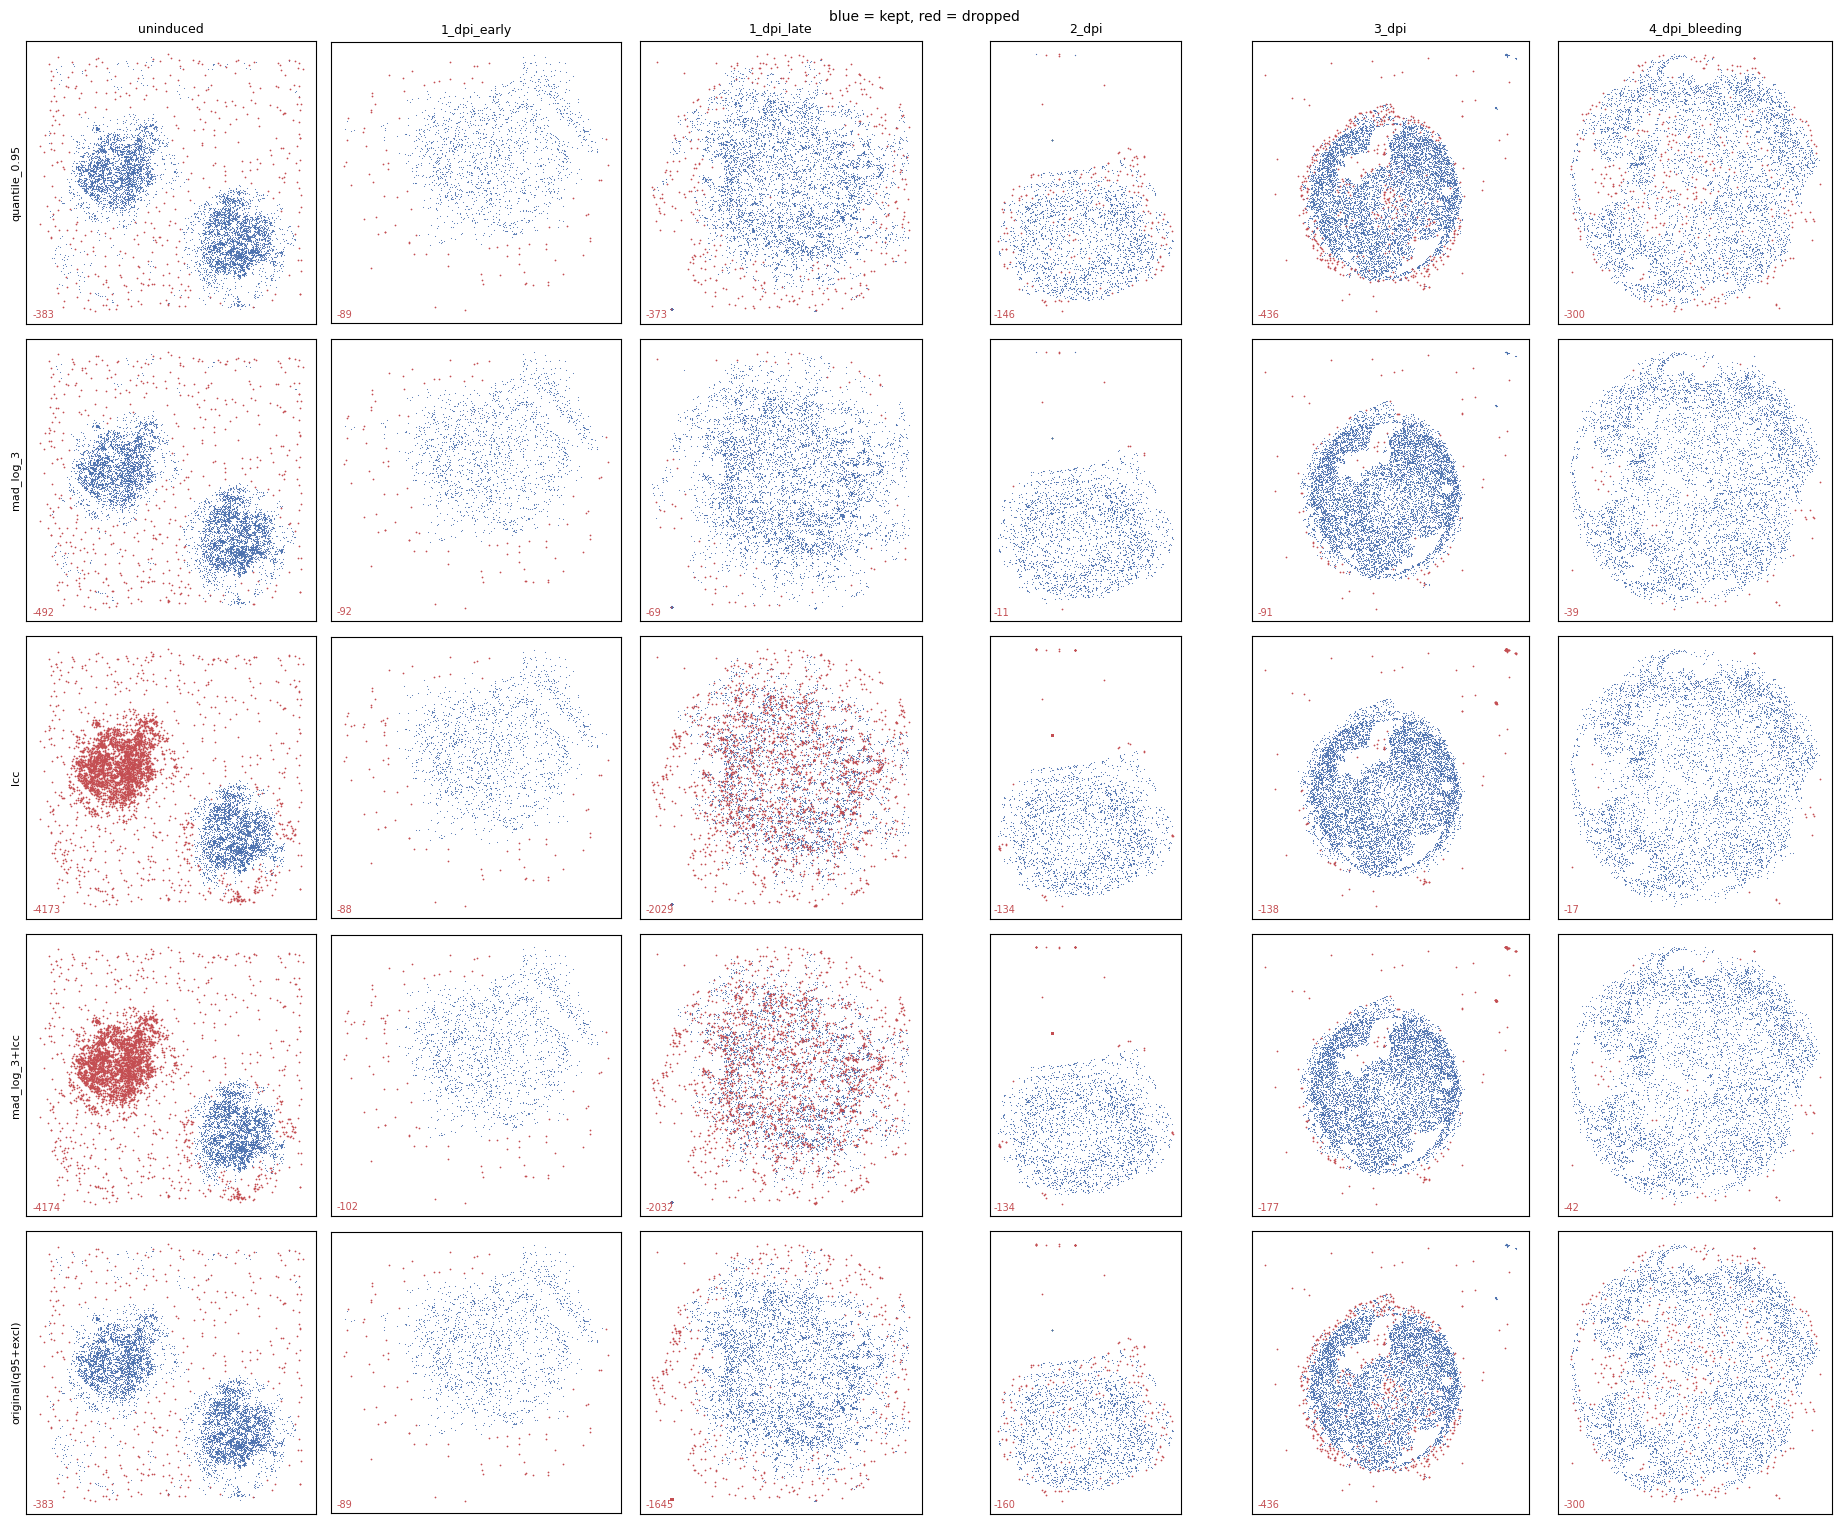

In [8]:
SHOW = ["quantile_0.95", "mad_log_3", "lcc", "mad_log_3+lcc", "original(q95+excl)"]
tps = [t for t in ["uninduced","1_dpi_early","1_dpi_late","2_dpi","3_dpi","4_dpi_bleeding"]
       if t in set(obs[TIMEPOINT].astype(str))]
fig, axes = plt.subplots(len(SHOW), len(tps), figsize=(3.1*len(tps), 3.1*len(SHOW)),
                         squeeze=False)
for i, name in enumerate(SHOW):
    drop = METHODS[name]
    for j, t in enumerate(tps):
        ax = axes[i][j]
        m = (obs[TIMEPOINT].astype(str) == t) & mapped
        sub, dd = obs.loc[m], drop[m]
        ax.scatter(sub.loc[~dd, X], sub.loc[~dd, Y], s=0.6, c="#4C72B0", linewidths=0)
        ax.scatter(sub.loc[dd, X],  sub.loc[dd, Y],  s=1.6, c="#C44E52", linewidths=0)
        ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
        if i == 0: ax.set_title(t, fontsize=9)
        if j == 0: ax.set_ylabel(name, fontsize=8)
        ax.text(0.02, 0.02, f"-{int(dd.sum())}", transform=ax.transAxes,
                fontsize=7, color="#C44E52")
fig.suptitle("blue = kept, red = dropped", fontsize=10)
fig.tight_layout(); plt.show()

## 9. Score distributions — is there a natural cut?

If the histogram is unimodal with a long tail, MAD-on-log is the right tool.
If it's bimodal, an absolute cutoff at the trough is more defensible.

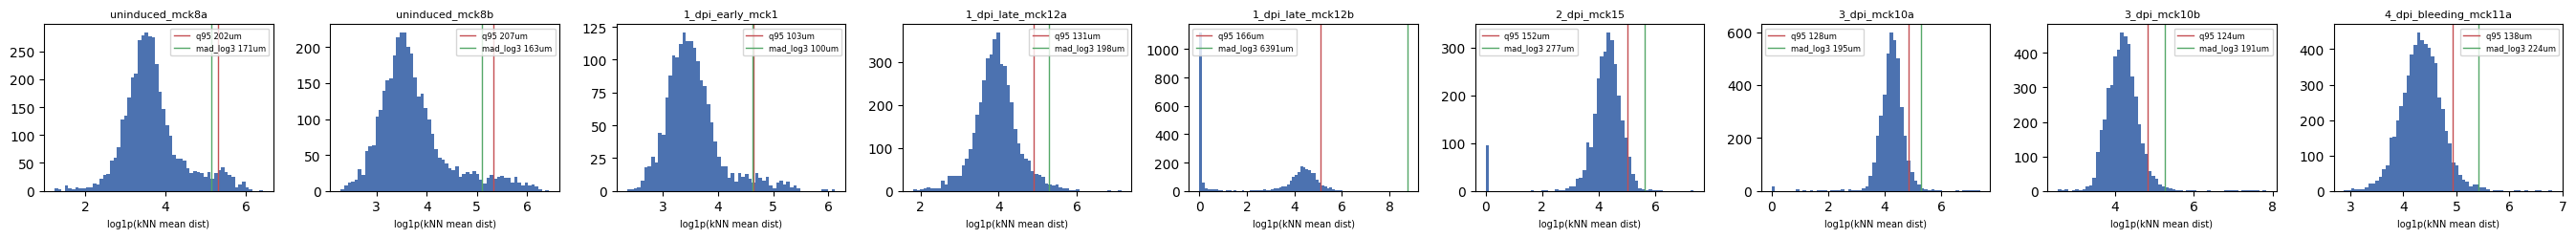

In [9]:
smp = obs.loc[mapped, SAMPLE].astype(str).unique()
fig, axes = plt.subplots(1, len(smp), figsize=(3*len(smp), 2.6), squeeze=False)
for ax, s in zip(axes[0], smp):
    d = obs_s.loc[mapped & (obs[SAMPLE].astype(str) == s), "score"].to_numpy(float)
    ax.hist(np.log1p(d), bins=60, color="#4C72B0")
    for lab, t, c in [("q95", np.quantile(d, 0.95), "#C44E52"),
                      ("mad_log3", mad_thresh(d, 3.0, log=True), "#55A868")]:
        ax.axvline(np.log1p(t), color=c, lw=1, label=f"{lab} {t:.0f}um")
    ax.set_title(s, fontsize=8); ax.set_xlabel("log1p(kNN mean dist)", fontsize=7)
    ax.legend(fontsize=6)
fig.tight_layout(); plt.show()

cells sharing an exact coordinate with >=1 other cell: 1,250 / 34,460 (3.6%)

pile-up size distribution (cells per occupied coordinate):
n_at_coord
1     33210
2        63
3        20
4         7
5         6
6         5
7         3
8         2
9         5
10        2
11        2
12        1

threshold with vs without the piled-up cells:
                          n  d==0  d<1um  in_collision  median_all  median_nodup  madlog3_all  madlog3_nodup
sample                                                                                                      
uninduced_mck8a        4075     0      0            28        34.6          34.7        171.1          172.2
uninduced_mck8b        3573     0      0            12        35.5          35.5        162.8          162.7
1_dpi_early_mck1       1775     0      0             0        31.1          31.1        100.4          100.4
1_dpi_late_mck12a      4348     0      0             0        50.0          50.0        198.0          198.0
1_dpi_l

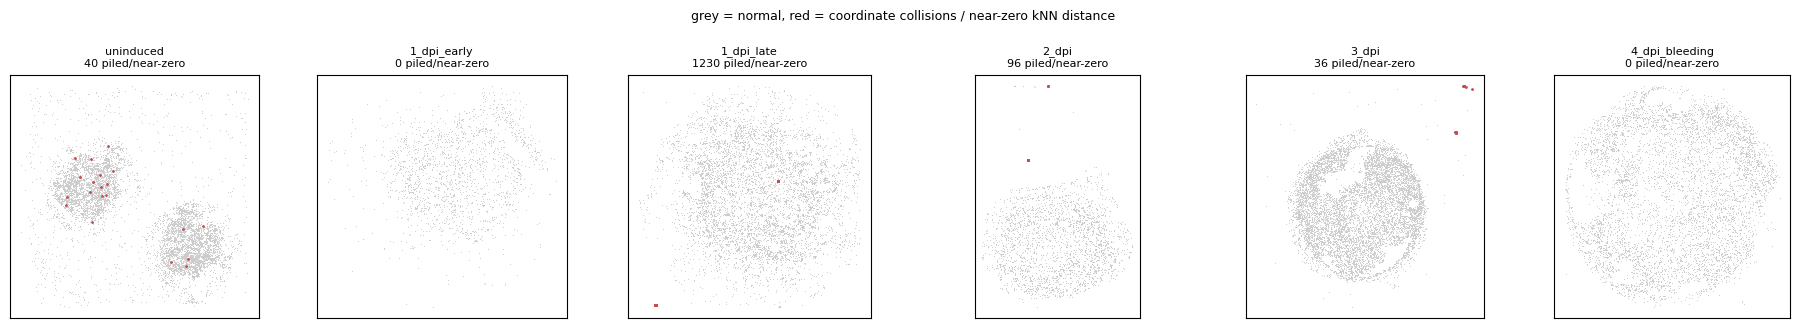

In [10]:
# ---- low-end outliers: cells piled at (near-)identical coordinates ----------
import numpy as np, pandas as pd, matplotlib.pyplot as plt

lo = obs_s.loc[mapped].copy()

# 1. exact coordinate collisions
grp = lo.groupby([SAMPLE, X, Y], observed=True).size().rename("n_at_coord")
lo["n_at_coord"] = lo.set_index([SAMPLE, X, Y]).index.map(grp).values
print("cells sharing an exact coordinate with >=1 other cell: "
      f"{int((lo.n_at_coord > 1).sum()):,} / {len(lo):,} ({100*(lo.n_at_coord>1).mean():.1f}%)")
print("\npile-up size distribution (cells per occupied coordinate):")
print(grp.value_counts().sort_index().head(12).to_string())

# 2. per sample: zero-ish kNN distance + collisions + what it does to the stats
rows = []
for s in lo[SAMPLE].astype(str).unique():
    m = lo[SAMPLE].astype(str) == s
    d = lo.loc[m, "score"].to_numpy(float)
    dup = lo.loc[m, "n_at_coord"].to_numpy() > 1
    d_clean = d[~dup]
    def mad_log(v, n=3.0):
        if len(v) < 10: return np.nan
        lv = np.log1p(v); med = np.median(lv); mad = np.median(np.abs(lv - med))
        return float(np.expm1(med + n * 1.4826 * mad))
    rows.append({"sample": s, "n": int(m.sum()),
                 "d==0": int((d == 0).sum()), "d<1um": int((d < 1).sum()),
                 "in_collision": int(dup.sum()),
                 "median_all": round(float(np.median(d)), 1),
                 "median_nodup": round(float(np.median(d_clean)), 1) if len(d_clean) else np.nan,
                 "madlog3_all": round(mad_log(d), 1),
                 "madlog3_nodup": round(mad_log(d_clean), 1)})
print("\nthreshold with vs without the piled-up cells:")
print(pd.DataFrame(rows).set_index("sample").to_string())

# 3. where are they?
tps = [t for t in ["uninduced","1_dpi_early","1_dpi_late","2_dpi","3_dpi","4_dpi_bleeding"]
       if t in set(obs[TIMEPOINT].astype(str))]
fig, axes = plt.subplots(1, len(tps), figsize=(3.1*len(tps), 3.3), squeeze=False)
for ax, t in zip(axes[0], tps):
    m = lo[TIMEPOINT].astype(str) == t
    sub = lo[m]; hit = (sub.n_at_coord > 1) | (sub.score < 1)
    ax.scatter(sub.loc[~hit, X], sub.loc[~hit, Y], s=0.6, c="#cccccc", linewidths=0)
    ax.scatter(sub.loc[hit, X],  sub.loc[hit, Y],  s=3, c="#C44E52", linewidths=0)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{t}\n{int(hit.sum())} piled/near-zero", fontsize=8)
fig.suptitle("grey = normal, red = coordinate collisions / near-zero kNN distance", fontsize=9)
fig.tight_layout(); plt.show()

In [11]:
big = (obs_s.loc[mapped].groupby([SAMPLE, X, Y], observed=True).size()
       .sort_values(ascending=False).head(8))
print(big.to_string())

sample             x_um_dbscan  y_um_dbscan
1_dpi_late_mck12b  734.562500   125.931570     202
2_dpi_mck15        4791.318000  6943.167000     90
1_dpi_late_mck12b  736.961071   126.117616      56
                   736.661250   126.094360      45
                   736.428056   126.076272      43
                   737.920500   126.192034      36
                   736.241500   126.061802      32
                   736.088864   126.049963      32


In [12]:
deg = obs_s.loc[mapped & (obs_s.score < 1)]
ok  = obs_s.loc[mapped & (obs_s.score >= 1) & (obs[SAMPLE] == "1_dpi_late_mck12b")]
print(deg.groupby(SAMPLE)[["n_genes_by_counts","total_counts"]].median().to_string())
print("\nsame puck, non-degenerate:")
print(ok[["n_genes_by_counts","total_counts"]].median().to_string())

                       n_genes_by_counts  total_counts
sample                                                
1_dpi_early_mck1                     NaN           NaN
1_dpi_late_mck12a                    NaN           NaN
1_dpi_late_mck12b                 1481.5        2416.0
2_dpi_mck15                       2008.0        2954.0
3_dpi_mck10a                       864.0        1040.0
3_dpi_mck10b                         NaN           NaN
4_dpi_bleeding_mck11a                NaN           NaN
uninduced_mck8a                      NaN           NaN
uninduced_mck8b                      NaN           NaN

same puck, non-degenerate:
n_genes_by_counts    1999.5
total_counts         3713.0


In [13]:
# ---- pick the physical floor: is there a gap between degenerate and real? ----
import numpy as np, pandas as pd
lo = obs_s.loc[mapped]
cuts = [0.5, 1, 2, 5, 10, 15, 20, 30]
rows = []
for s in lo[SAMPLE].astype(str).unique():
    d = lo.loc[lo[SAMPLE].astype(str) == s, "score"].to_numpy(float)
    r = {"sample": s, "n": len(d), "median": round(float(np.median(d)), 1)}
    for c in cuts:
        r[f"<{c}um"] = int((d < c).sum())
    # two-sided log-MAD bounds, for comparison
    lv = np.log1p(d); med = np.median(lv); mad = np.median(np.abs(lv - med))
    r["logMAD_lo"] = round(float(np.expm1(med - 3*1.4826*mad)), 1)
    r["logMAD_hi"] = round(float(np.expm1(med + 3*1.4826*mad)), 1)
    rows.append(r)
print(pd.DataFrame(rows).set_index("sample").to_string())

# and the same AFTER dropping <1um and recomputing -- the honest thresholds
print("\nafter dropping <1um and recomputing kNN on survivors:")
rows = []
for s in lo[SAMPLE].astype(str).unique():
    m = mapped & (obs[SAMPLE].astype(str) == s) & (obs_s["score"] >= 1)
    xy = obs.loc[m, [X, Y]].to_numpy(float)
    if xy.shape[0] < 20: continue
    d = knn_mean_dist(xy)
    lv = np.log1p(d); med = np.median(lv); mad = np.median(np.abs(lv - med))
    rows.append({"sample": s, "n": int(m.sum()), "median": round(float(np.median(d)), 1),
                 "logMAD_lo": round(float(np.expm1(med - 3*1.4826*mad)), 1),
                 "logMAD_hi": round(float(np.expm1(med + 3*1.4826*mad)), 1),
                 "would_drop_hi": int((d > np.expm1(med + 3*1.4826*mad)).sum())})
print(pd.DataFrame(rows).set_index("sample").to_string())

                          n  median  <0.5um  <1um  <2um  <5um  <10um  <15um  <20um  <30um  logMAD_lo  logMAD_hi
sample                                                                                                         
uninduced_mck8a        4075    34.6       0     0     0    25     91    256    603   1584        6.3      171.1
uninduced_mck8b        3573    35.5       0     0     0     0      5    102    385   1263        7.1      162.8
1_dpi_early_mck1       1775    31.1       0     0     0     0      1     50    195    831        9.2      100.4
1_dpi_late_mck12a      4348    50.0       0     0     0     0     30    108    218    627       12.1      198.0
1_dpi_late_mck12b      3086    47.3    1208  1230  1249  1261   1279   1299   1313   1367       -0.6     6390.6
2_dpi_mck15            2909    74.0      96    96    96    97    101    105    118    185       19.2      277.3
3_dpi_mck10a           4110    69.8      17    17    22    31     38     48     53     84       24.6    

In [18]:
# ---- PROPOSED FILTER (per TIMEPOINT), absolute floor + upper log-MAD --------
FLOOR_UM = 10.0      # physical floor: cells ~10um, beads ~10um apart
N_MADS   = 3.0       # upper tail only -- that one IS density-relative
MAX_AT_COORD = 1

reason = pd.Series("kept", index=obs.index, dtype=object)
reason[~mapped] = "unmapped"

# duplicates: still checked PER SAMPLE (pucks are separate coordinate frames,
# so an identical coordinate in two replicates is coincidence, not a pile-up)
key = (obs[SAMPLE].astype(str) + "|" + obs[X].astype(str) + "|" + obs[Y].astype(str))
n_at = key.map(key[mapped].value_counts()).fillna(0)
degen = mapped & ((n_at > MAX_AT_COORD) | (obs_s["score"] < FLOOR_UM))
reason[degen] = "degenerate"

# upper tail: grouped by TIMEPOINT, recomputed on survivors
surv = mapped & ~degen
score2 = pd.Series(np.nan, index=obs.index); thr_hi = {}
for t in obs.loc[surv, TIMEPOINT].astype(str).unique():
    m = surv & (obs[TIMEPOINT].astype(str) == t)
    d = knn_mean_dist(obs.loc[m, [X, Y]].to_numpy(float)); score2.loc[m] = d
    lv = np.log1p(d); med = np.median(lv); mad = np.median(np.abs(lv - med))
    thr_hi[t] = float(np.expm1(med + N_MADS * 1.4826 * mad))
    reason[m & (score2 > thr_hi[t])] = "far"

obs_f = obs.assign(reason=reason.values, score2=score2.values)
ORDER = ["kept", "far", "degenerate", "unmapped"]
COL = {"kept": "#7f9fc4", "far": "#DD8452", "degenerate": "#C44E52", "unmapped": "#bbbbbb"}

tab = (obs_f.groupby([TIMEPOINT, "reason"], observed=True).size().unstack(fill_value=0)
       .reindex(columns=ORDER, fill_value=0))
tab["total"] = tab.sum(axis=1)
tab["kept_%"] = (100 * tab["kept"] / tab["total"]).round(1)
tab["thr_hi_um"] = pd.Series(thr_hi).round(0)
tab["median_after"] = obs_f[obs_f.reason == "kept"].groupby(TIMEPOINT, observed=True)["score2"].median().round(1)
print(f"floor={FLOOR_UM}um  n_mads={N_MADS}  (MAD per timepoint, dups per sample)\n")
print(tab.to_string())

# per-puck breakdown, so a bad replicate can't hide inside a good timepoint
print("\nper puck:")
pt = (obs_f.groupby([TIMEPOINT, SAMPLE, "reason"], observed=True).size().unstack(fill_value=0)
      .reindex(columns=ORDER, fill_value=0))
pt["total"] = pt.sum(axis=1); pt["kept_%"] = (100 * pt["kept"] / pt["total"]).round(1)
print(pt.to_string())

print(f"\nTOTAL kept {int((reason=='kept').sum()):,} / {len(obs):,} "
      f"({100*(reason=='kept').mean():.1f}%)   degenerate {int(degen.sum()):,}  "
      f"far {int((reason=='far').sum()):,}  unmapped {int((~mapped).sum()):,}")

floor=10.0um  n_mads=3.0  (MAD per timepoint, dups per sample)

reason          kept  far  degenerate  unmapped  total  kept_%  thr_hi_um  median_after
timepoint                                                                              
1_dpi_early     1681   93           1      1683   3458    48.6      100.0          30.2
1_dpi_late      6054   71        1309      6923  14357    42.2      177.0          42.2
2_dpi           2793   15         101      2105   5014    55.7      269.0          75.2
3_dpi           8548  101          49      7771  16469    51.9      134.0          46.8
4_dpi_bleeding  5957   39           0      2437   8433    70.6      224.0          75.8
uninduced       7043  473         132     12690  20338    34.6      123.0          24.0

per puck:
reason                                kept  far  degenerate  unmapped  total  kept_%
timepoint      sample                                                               
1_dpi_early    1_dpi_early_mck1       1681   93    

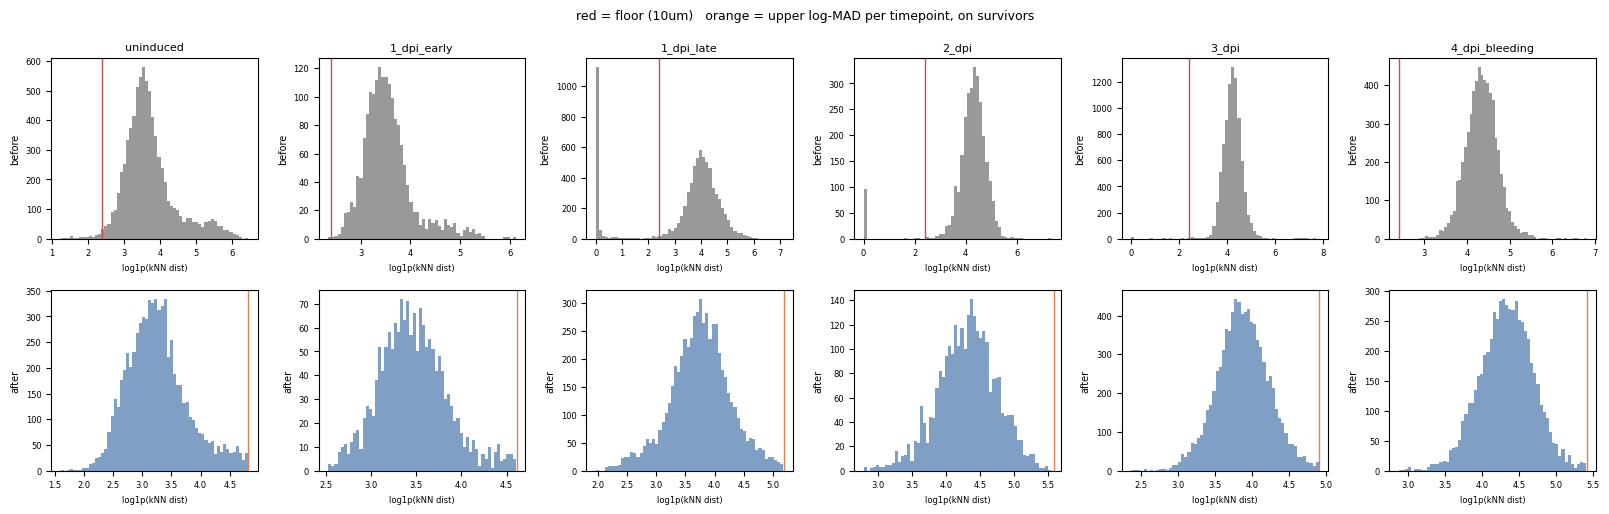

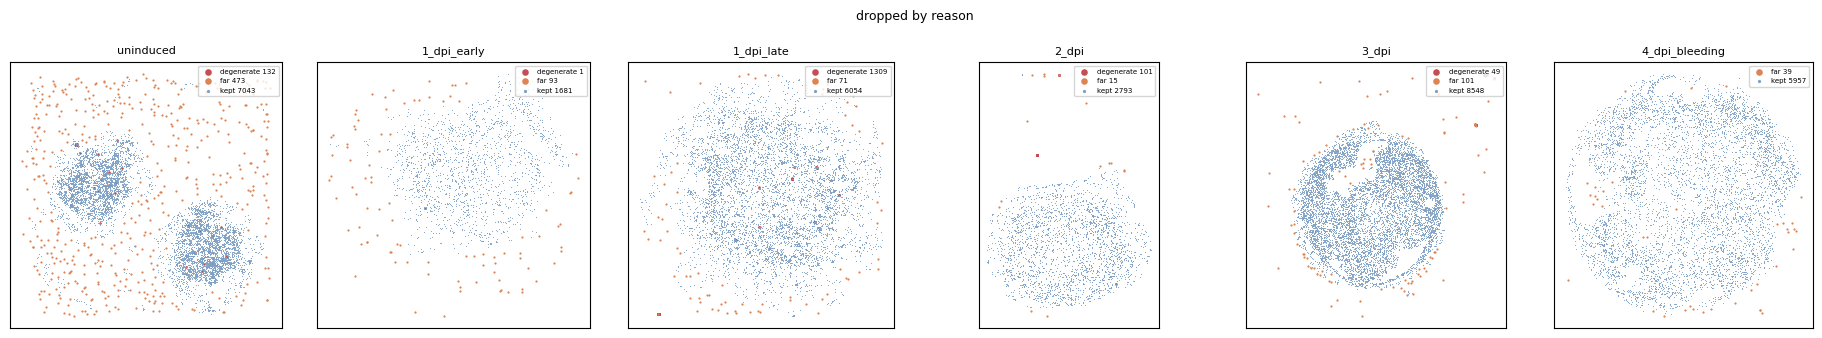

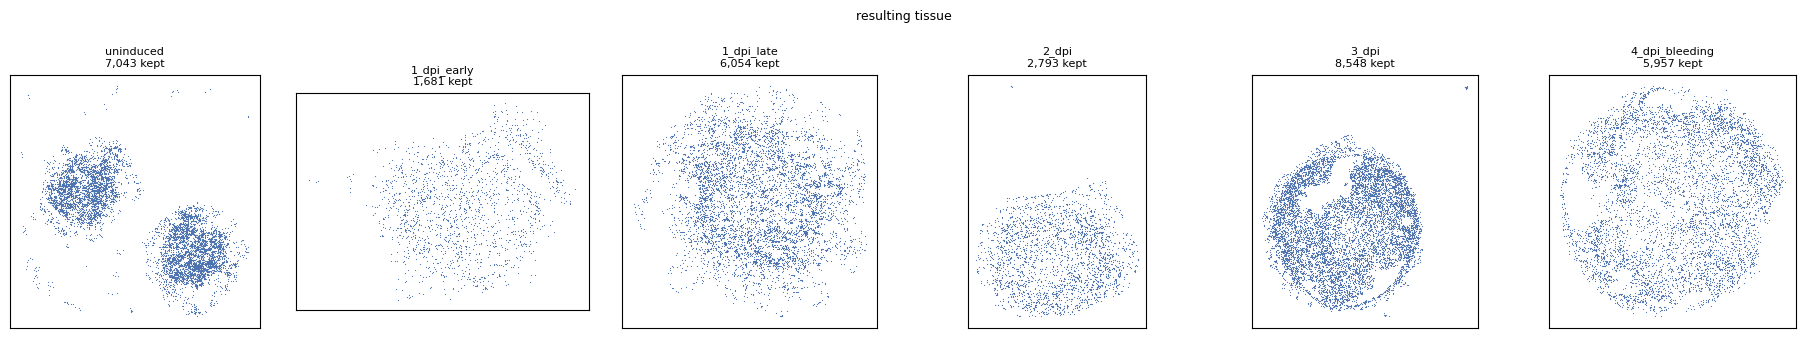

In [19]:
TPS = [t for t in ["uninduced","1_dpi_early","1_dpi_late","2_dpi","3_dpi","4_dpi_bleeding"]
       if t in set(obs[TIMEPOINT].astype(str))]

# 1. score distributions, floor + ceiling drawn
fig, axes = plt.subplots(2, len(TPS), figsize=(2.7*len(TPS), 5.2), squeeze=False)
for j, t in enumerate(TPS):
    m = mapped & (obs[TIMEPOINT].astype(str) == t)
    axes[0][j].hist(np.log1p(obs_s.loc[m, "score"].to_numpy(float)), bins=60, color="#999999")
    axes[0][j].axvline(np.log1p(FLOOR_UM), color="#C44E52", lw=1)
    axes[0][j].set_title(t, fontsize=8); axes[0][j].set_ylabel("before", fontsize=7)
    mk = obs_f.reason.eq("kept").values & m.values
    if mk.sum():
        axes[1][j].hist(np.log1p(obs_f.loc[mk, "score2"].to_numpy(float)), bins=60, color="#7f9fc4")
        axes[1][j].axvline(np.log1p(thr_hi[t]), color="#DD8452", lw=1)
    axes[1][j].set_ylabel("after", fontsize=7)
    for ax in (axes[0][j], axes[1][j]):
        ax.tick_params(labelsize=6); ax.set_xlabel("log1p(kNN dist)", fontsize=6)
fig.suptitle("red = floor (10um)   orange = upper log-MAD per timepoint, on survivors", fontsize=9)
fig.tight_layout(); plt.show()

# 2. what gets dropped, and why
fig, axes = plt.subplots(1, len(TPS), figsize=(3.1*len(TPS), 3.4), squeeze=False)
for ax, t in zip(axes[0], TPS):
    sub = obs_f.loc[mapped & (obs[TIMEPOINT].astype(str) == t)]
    for r in ORDER[::-1]:
        p = sub[sub.reason == r]
        if len(p):
            ax.scatter(p[X], p[Y], s=(0.6 if r == "kept" else 2.5), c=COL[r],
                       linewidths=0, label=f"{r} {len(p)}")
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(t, fontsize=8); ax.legend(fontsize=5, markerscale=3, loc="upper right")
fig.suptitle("dropped by reason", fontsize=9); fig.tight_layout(); plt.show()

# 3. the resulting tissue
fig, axes = plt.subplots(1, len(TPS), figsize=(3.1*len(TPS), 3.4), squeeze=False)
for ax, t in zip(axes[0], TPS):
    p = obs_f.loc[obs_f.reason.eq("kept") & (obs[TIMEPOINT].astype(str) == t)]
    ax.scatter(p[X], p[Y], s=0.7, c="#4C72B0", linewidths=0)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{t}\n{len(p):,} kept", fontsize=8)
fig.suptitle("resulting tissue", fontsize=9); fig.tight_layout(); plt.show()

In [17]:
# ---- per-SAMPLE vs per-TIMEPOINT grouping: does it actually matter? ---------
def run_group(group_key, floor=10.0, n_mads=3.0):
    """Returns (reason series, thresholds dict) for a given grouping column."""
    rsn = pd.Series("kept", index=obs.index, dtype=object)
    rsn[~mapped] = "unmapped"
    key = (obs[group_key].astype(str) + "|" + obs[X].astype(str) + "|" + obs[Y].astype(str))
    n_at = key.map(key[mapped].value_counts()).fillna(0)
    dg = mapped & ((n_at > 1) | (obs_s["score"] < floor))
    rsn[dg] = "degenerate"
    sv = mapped & ~dg
    thr = {}
    for g in obs.loc[sv, group_key].astype(str).unique():
        m = sv & (obs[group_key].astype(str) == g)
        d = knn_mean_dist(obs.loc[m, [X, Y]].to_numpy(float))
        lv = np.log1p(d); med = np.median(lv); mad = np.median(np.abs(lv - med))
        thr[g] = float(np.expm1(med + n_mads * 1.4826 * mad))
        rsn[m & pd.Series(d > thr[g], index=obs.index[m.values])] = "far"
    return rsn, thr

r_smp, t_smp = run_group(SAMPLE)
r_tp,  t_tp  = run_group(TIMEPOINT)

print("thresholds (um):")
comp = pd.DataFrame({"per_sample": pd.Series(t_smp)})
comp["timepoint"] = [obs.loc[obs[SAMPLE].astype(str) == s, TIMEPOINT].iloc[0] for s in comp.index]
comp["per_timepoint"] = comp["timepoint"].map(t_tp)
comp["ratio"] = (comp.per_timepoint / comp.per_sample).round(2)
print(comp.round(0).to_string())

chg = (r_smp != r_tp)
print(f"\ncells whose fate CHANGES between groupings: {int(chg.sum()):,} "
      f"({100*chg.mean():.2f}%)")
if chg.any():
    print(pd.crosstab(r_smp[chg], r_tp[chg]).to_string())
    print("\nby sample:")
    print(obs.loc[chg].groupby(SAMPLE, observed=True).size().to_string())

thresholds (um):
                       per_sample       timepoint  per_timepoint  ratio
uninduced_mck8a             164.0       uninduced          123.0    1.0
uninduced_mck8b             162.0       uninduced          123.0    1.0
1_dpi_early_mck1            100.0     1_dpi_early          100.0    1.0
1_dpi_late_mck12a           197.0      1_dpi_late          177.0    1.0
1_dpi_late_mck12b           372.0      1_dpi_late          177.0    0.0
2_dpi_mck15                 269.0           2_dpi          269.0    1.0
3_dpi_mck10a                193.0           3_dpi          134.0    1.0
3_dpi_mck10b                191.0           3_dpi          134.0    1.0
4_dpi_bleeding_mck11a       224.0  4_dpi_bleeding          224.0    1.0

cells whose fate CHANGES between groupings: 240 (0.35%)
col_0  degenerate  far  kept
row_0                       
far             7    0   117
kept           34   82     0

by sample:
sample
1_dpi_late_mck12a    32
1_dpi_late_mck12b    25
3_dpi_mck10a         23

In [20]:
# ---- WHAT are we removing? join the finest available label to every cell ------
SUB = Path("/n/eddy_lab/users/nhilgert/decidualization/revisions/adatas/submission")

def _canon(s):
    s = s.astype(str).str.lower().str.replace(r"[^a-z0-9]", "", regex=True)
    return s.str.replace("bleeding", "menstrual", regex=False)
def _key(o):
    return _canon(o["sample"]) + "||" + \
           o["cell_barcode"].astype(str).str.replace(r"-\d+$", "", regex=True)

mykey = _key(obs)
coarse_ref = sc.read_h5ad(SUB/"20251008_Cevrim_XMens_All_Cells.h5ad", backed="r").obs.copy()
fine_ref   = sc.read_h5ad(SUB/"20251008_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad", backed="r").obs.copy()
coarse_ref["k"] = _key(coarse_ref); fine_ref["k"] = _key(fine_ref)

coarse = mykey.map(coarse_ref.set_index("k")["cell_type_annotations"]).astype(object)
fine   = mykey.map(fine_ref.set_index("k")["cell_subtype_annotations"]).astype(object)
label  = fine.where(fine.notna(), coarse).fillna("unlabeled")   # finest available
obs_f["label"], obs_f["coarse"] = label.values, coarse.fillna("unlabeled").values
print(f"labelled {int((label!='unlabeled').sum()):,}/{len(obs):,}, "
      f"with fine subtype {int(fine.notna().sum()):,}")

base = (obs_f.reason != "kept").mean()
ct = pd.crosstab(obs_f["label"], obs_f["reason"]).reindex(columns=ORDER, fill_value=0)
ct["total"] = ct.sum(axis=1)
ct["removed_%"] = (100 * (ct["total"] - ct["kept"]) / ct["total"]).round(1)
ct["enrichment"] = (((ct["total"] - ct["kept"]) / ct["total"]) / base).round(2)
print(f"\nbaseline removal {100*base:.1f}%  (enrichment >1.5 = over-removed)")
print(ct.sort_values("enrichment", ascending=False).to_string())

print("\nremoved % by coarse type x timepoint:")
print((obs_f.assign(rm=obs_f.reason != "kept")
       .pivot_table(index="coarse", columns=TIMEPOINT, values="rm", aggfunc="mean")
       .mul(100).round(1)).to_string())

# is it an EDGE effect? perimetrium/myometrium live at the edge by construction
d_cent = pd.Series(np.nan, index=obs.index)
for s in obs.loc[mapped, SAMPLE].astype(str).unique():
    m = mapped & (obs[SAMPLE].astype(str) == s)
    xy = obs.loc[m, [X, Y]].to_numpy(float); c = np.median(xy, axis=0)
    r = np.sqrt(((xy - c) ** 2).sum(1)); d_cent.loc[m] = r / np.quantile(r, 0.99)
obs_f["r_norm"] = d_cent.values
bins = pd.cut(obs_f["r_norm"], [0,.2,.4,.6,.8,1.0,1.5,np.inf],
              labels=["0-.2",".2-.4",".4-.6",".6-.8",".8-1","1-1.5",">1.5"])
print("\nremoval rate by normalised distance from centre (1.0 ~ edge):")
print((obs_f.assign(rm=obs_f.reason != "kept", shell=bins)
       .groupby("shell", observed=True)["rm"].agg(["size","mean"])
       .assign(mean=lambda d: (100*d["mean"]).round(1))).to_string())
print("\nmedian r_norm per coarse type (edge types most at risk):")
print(obs_f[obs_f.coarse != "unlabeled"].groupby("coarse", observed=True)["r_norm"]
      .median().round(2).sort_values(ascending=False).to_string())

labelled 56,804/68,069, with fine subtype 42,703

baseline removal 52.9%  (enrichment >1.5 = over-removed)
reason               kept  far  degenerate  unmapped  total  removed_%  enrichment
label                                                                             
unlabeled            2625  107         326      8207  11265       76.7        1.45
perimetrium cells     194   60           5       392    651       70.2        1.33
smooth muscle cells   485   70          33       987   1575       69.2        1.31
epithelial cells     2544  135         140      3577   6396       60.2        1.14
immune cells          840   36          58      1137   2071       59.4        1.12
eFib2                2269   97          19      3024   5409       58.1        1.10
eFib1                 877   74          49       996   1996       56.1        1.06
eFib3                1597   51          94      1807   3549       55.0        1.04
eFibP                 494   13          30       503   1040    

In [21]:
# ---- is the `far` cut a boundary artifact? sweep thresholds + try LOF --------
from sklearn.neighbors import LocalOutlierFactor

surv = mapped & ~degen                      # degenerate stage is not in question
lab  = obs_f["coarse"]                       # from the composition cell
TARGET = ["perimetrium cells", "smooth muscle cells"]

def report(name, far_mask):
    rm = far_mask & surv
    base = rm[surv].mean()
    out = {"setting": name, "far": int(rm.sum()), "far_%": round(100*base, 2)}
    for t in TARGET:
        m = surv & (lab == t)
        out[t.split()[0]] = round(float(rm[m].mean() / base), 2) if m.sum() else np.nan
    worst = (pd.DataFrame({"t": lab[surv], "r": rm[surv]}).groupby("t")["r"].mean() / base)
    out["most_enriched"] = f"{worst.idxmax()} {worst.max():.1f}x"
    return out

rows = []
for n in [3.0, 3.5, 4.0, 5.0]:
    fm = pd.Series(False, index=obs.index)
    for t in obs.loc[surv, TIMEPOINT].astype(str).unique():
        m = surv & (obs[TIMEPOINT].astype(str) == t)
        d = knn_mean_dist(obs.loc[m, [X, Y]].to_numpy(float))
        lv = np.log1p(d); med = np.median(lv); mad = np.median(np.abs(lv - med))
        fm.loc[m] = d > np.expm1(med + n * 1.4826 * mad)
    rows.append(report(f"logMAD n={n}", fm))

for nn, cut in [(20, 1.5), (20, 2.0), (50, 1.5)]:
    fm = pd.Series(False, index=obs.index)
    for t in obs.loc[surv, TIMEPOINT].astype(str).unique():
        m = surv & (obs[TIMEPOINT].astype(str) == t)
        xy = obs.loc[m, [X, Y]].to_numpy(float)
        if xy.shape[0] <= nn + 1: continue
        clf = LocalOutlierFactor(n_neighbors=nn).fit(xy)
        fm.loc[m] = (-clf.negative_outlier_factor_) > cut
    rows.append(report(f"LOF k={nn} >{cut}", fm))

print("enrichment 1.0 = removed at the population rate; >2 = penalised\n")
print(pd.DataFrame(rows).set_index("setting").to_string())

enrichment 1.0 = removed at the population rate; >2 = penalised

               far  far_%  perimetrium  smooth            most_enriched
setting                                                                
logMAD n=3.0   792   2.41         9.80    5.23   perimetrium cells 9.8x
logMAD n=3.5   514   1.56         8.06    5.18   perimetrium cells 8.1x
logMAD n=4.0   283   0.86         8.23    4.19   perimetrium cells 8.2x
logMAD n=5.0    65   0.20         1.99    0.00           unlabeled 2.2x
LOF k=20 >1.5  323   0.98         9.61    4.77   perimetrium cells 9.6x
LOF k=20 >2.0   95   0.29         5.45    3.12   perimetrium cells 5.4x
LOF k=50 >1.5  455   1.38        17.35    5.99  perimetrium cells 17.3x


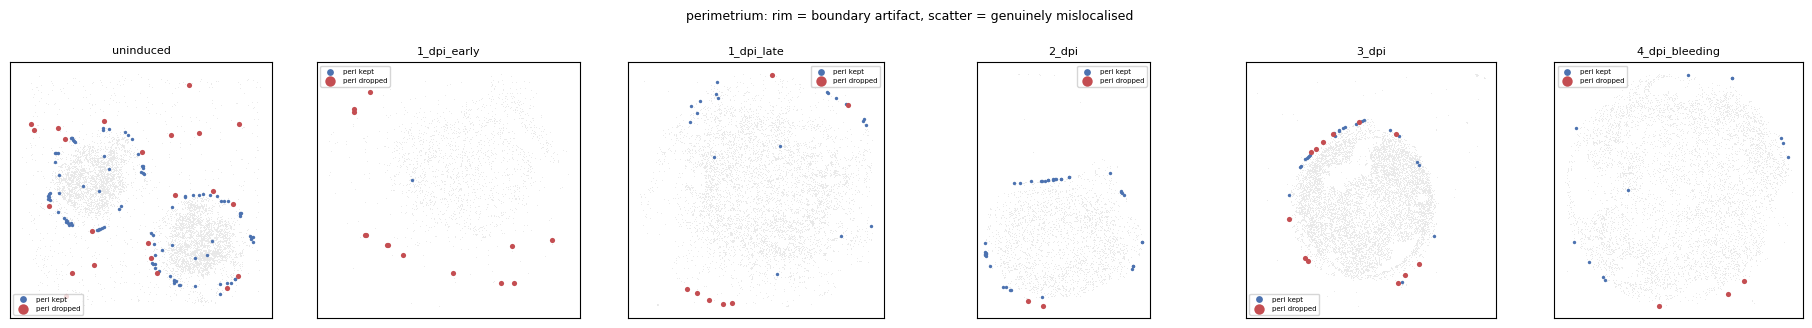

In [22]:
peri = surv & (lab == "perimetrium cells")
fig, axes = plt.subplots(1, len(TPS), figsize=(3.1*len(TPS), 3.3), squeeze=False)
for ax, t in zip(axes[0], TPS):
    m = mapped & (obs[TIMEPOINT].astype(str) == t)
    ax.scatter(obs.loc[m, X], obs.loc[m, Y], s=0.4, c="#e8e8e8", linewidths=0)
    p = peri & m
    ax.scatter(obs.loc[p & obs_f.reason.eq("kept"), X], obs.loc[p & obs_f.reason.eq("kept"), Y],
               s=6, c="#4C72B0", linewidths=0, label="peri kept")
    ax.scatter(obs.loc[p & obs_f.reason.eq("far"), X], obs.loc[p & obs_f.reason.eq("far"), Y],
               s=14, c="#C44E52", linewidths=0, label="peri dropped")
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(t, fontsize=8)
    ax.legend(fontsize=5, markerscale=2)
fig.suptitle("perimetrium: rim = boundary artifact, scatter = genuinely mislocalised", fontsize=9)
fig.tight_layout(); plt.show()

In [23]:
# ---- are the FLAGGED cells actually lower quality? ---------------------------
QC = [c for c in ["n_genes_by_counts", "total_counts", "pct_counts_mt",
                  "pct_counts_ribo", "doubletdetection_doublet_score"] if c in obs.columns]

print("=== 1. overall, by reason (medians) ===")
g = obs_f.groupby("reason", observed=True)[QC].median().round(1)
g["n"] = obs_f.groupby("reason", observed=True).size()
print(g.reindex(ORDER).to_string())

print("\n=== 2. WITHIN cell type: far vs kept (median ratio) ===")
print("ratio <1 = flagged cells are lower quality than kept cells of the SAME type")
rows = []
for t, sub in obs_f[obs_f.coarse != "unlabeled"].groupby("coarse", observed=True):
    k = sub[sub.reason == "kept"]; f = sub[sub.reason == "far"]
    if len(f) < 10 or len(k) < 10: continue
    r = {"coarse": t, "n_kept": len(k), "n_far": len(f)}
    for c in ["n_genes_by_counts", "total_counts"]:
        r[c.replace("_by_counts", "").replace("total_", "tot_")] = round(
            float(f[c].median() / k[c].median()), 2)
    if "doubletdetection_doublet_score" in QC:
        r["dbl_kept"] = round(float(k["doubletdetection_doublet_score"].median()), 2)
        r["dbl_far"]  = round(float(f["doubletdetection_doublet_score"].median()), 2)
    rows.append(r)
print(pd.DataFrame(rows).set_index("coarse").to_string())

print("\n=== 3. perimetrium in detail ===")
peri = obs_f[obs_f.coarse == "perimetrium cells"]
print(peri.groupby("reason", observed=True)[QC].median().round(1)
      .assign(n=peri.groupby("reason", observed=True).size()).to_string())
from scipy.stats import mannwhitneyu
k = peri[peri.reason == "kept"]["n_genes_by_counts"].dropna()
f = peri[peri.reason == "far"]["n_genes_by_counts"].dropna()
if len(k) > 5 and len(f) > 5:
    u, p = mannwhitneyu(f, k, alternative="two-sided")
    print(f"\nn_genes, far vs kept perimetrium: {f.median():.0f} vs {k.median():.0f}, p={p:.3g}")

print("\n=== 4. sanity check on the premise: are UNMAPPED cells lower quality? ===")
u = obs_f[obs_f.reason == "unmapped"]; m = obs_f[obs_f.reason == "kept"]
print(pd.DataFrame({"unmapped": u[QC].median(), "kept_mapped": m[QC].median(),
                    "ratio": (u[QC].median() / m[QC].median()).round(2)}).round(1).to_string())

=== 1. overall, by reason (medians) ===
            n_genes_by_counts  total_counts  pct_counts_mt  pct_counts_ribo  doubletdetection_doublet_score      n
reason                                                                                                            
kept                   1822.0        3247.0            0.0              0.3                             0.0  32076
far                    1371.0        2165.0            0.0              0.3                             0.0    792
degenerate             1579.0        2506.5            0.0              0.4                             0.1   1592
unmapped               1686.0        2850.0            0.0              0.3                             0.0  33609

=== 2. WITHIN cell type: far vs kept (median ratio) ===
ratio <1 = flagged cells are lower quality than kept cells of the SAME type
                         n_kept  n_far  n_genes  tot_counts  dbl_kept  dbl_far
coarse                                                    

-- mapped --
timepoint            uninduced  1_dpi_early  1_dpi_late  2_dpi  3_dpi  4_dpi_bleeding
type                                                                                 
eFib1                    337.0         39.0       212.0  125.0  223.0            64.0
perimetrium cells        125.0         14.0        29.0   41.0   35.0            15.0
smooth muscle cells      298.0         17.0        80.0  118.0   47.0            28.0

-- kept --
timepoint            uninduced  1_dpi_early  1_dpi_late  2_dpi  3_dpi  4_dpi_bleeding
type                                                                                 
eFib1                    298.0         30.0       155.0  124.0  212.0            58.0
perimetrium cells        100.0          1.0        19.0   39.0   23.0            12.0
smooth muscle cells      249.0          8.0        45.0  117.0   39.0            27.0

-- kept_of_mapped_% --
timepoint            uninduced  1_dpi_early  1_dpi_late  2_dpi  3_dpi  4_dpi_bleeding
type 

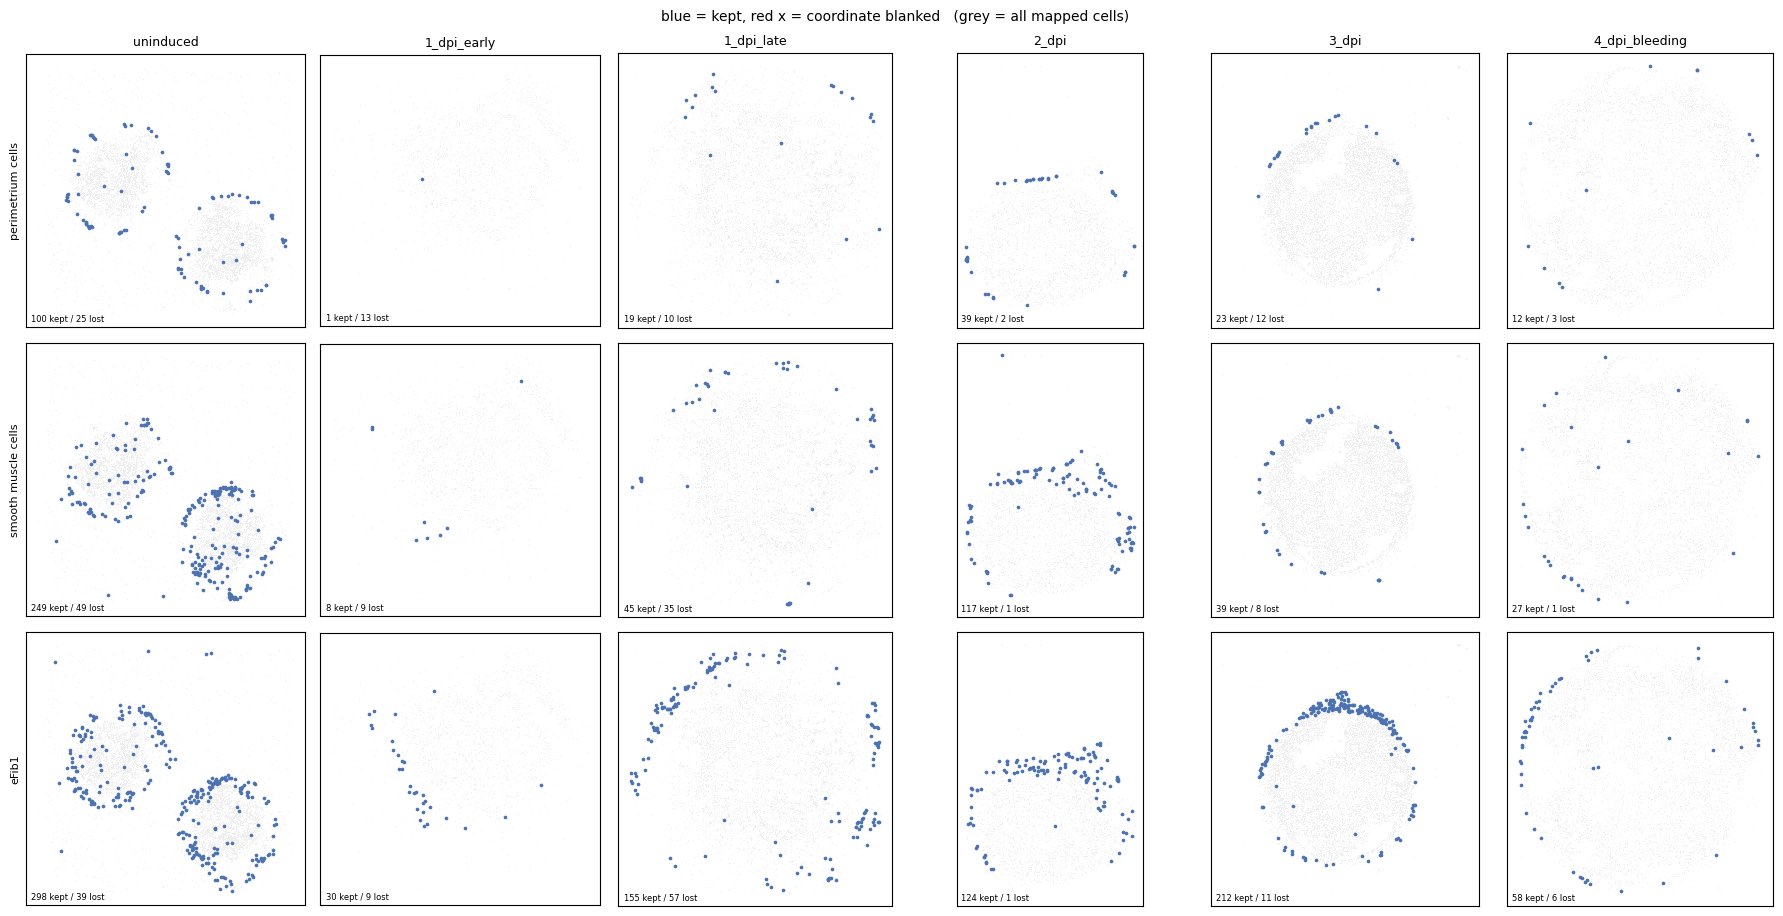

In [24]:
# ---- do the at-risk types survive, per timepoint? ---------------------------
TYPES = ["perimetrium cells", "smooth muscle cells", "eFib1"]

def type_mask(t):
    m = obs_f["coarse"].astype(str).eq(t)
    if "label" in obs_f: m = m | obs_f["label"].astype(str).eq(t)
    return m.values

rows = []
for t in TYPES:
    tm = type_mask(t)
    for tp in TPS:
        sel = tm & (obs[TIMEPOINT].astype(str) == tp).values
        mp, kept = sel & mapped.values, sel & obs_f.reason.eq("kept").values
        rows.append({"type": t, "timepoint": tp, "mapped": int(mp.sum()),
                     "kept": int(kept.sum()),
                     "kept_of_mapped_%": round(100*kept.sum()/max(mp.sum(),1), 1)})
cnt = pd.DataFrame(rows).pivot(index="type", columns="timepoint",
                               values=["mapped", "kept", "kept_of_mapped_%"])
for k in ["mapped", "kept", "kept_of_mapped_%"]:
    print(f"-- {k} --"); print(cnt[k].reindex(columns=TPS).to_string()); print()

fig, axes = plt.subplots(len(TYPES), len(TPS),
                         figsize=(3.0*len(TPS), 3.1*len(TYPES)), squeeze=False)
for i, t in enumerate(TYPES):
    tm = type_mask(t)
    for j, tp in enumerate(TPS):
        ax = axes[i][j]
        bg = mapped.values & (obs[TIMEPOINT].astype(str) == tp).values
        ax.scatter(obs.loc[bg, X], obs.loc[bg, Y], s=0.3, c="#ededed", linewidths=0)
        sel = tm & bg
        kp, dr = sel & obs_f.reason.eq("kept").values, sel & ~obs_f.reason.eq("kept").values
        ax.scatter(obs.loc[kp, X], obs.loc[kp, Y], s=7, c="#4C72B0", linewidths=0)
        ax.scatter(obs.loc[dr, X], obs.loc[dr, Y], s=16, c="#C44E52", linewidths=0, marker="x")
        ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
        if i == 0: ax.set_title(tp, fontsize=9)
        if j == 0: ax.set_ylabel(t, fontsize=8)
        ax.text(0.02, 0.02, f"{int(kp.sum())} kept / {int(dr.sum())} lost",
                transform=ax.transAxes, fontsize=6)
fig.suptitle("blue = kept, red x = coordinate blanked   (grey = all mapped cells)", fontsize=10)
fig.tight_layout(); plt.show()

radial profile before vs after (r_norm: 1.0 ~ tissue edge)
shift near 0 = only strays trimmed; large negative = the outer rim was cut

                                    n_before  n_after  r_med_before  r_med_after  r_p90_before  r_p90_after  r_med_shift
type                timepoint                                                                                           
perimetrium cells   uninduced            125      100          0.57         0.57          0.83         0.82         0.00
                    1_dpi_early           14        1          0.94         0.43          1.00         0.43        -0.51
                    1_dpi_late            29       19          0.99         0.95          1.09         1.09        -0.04
                    2_dpi                 41       39          0.81         0.82          0.88         0.88         0.01
                    3_dpi                 35       23          0.89         0.71          0.99         0.93        -0.18
                  

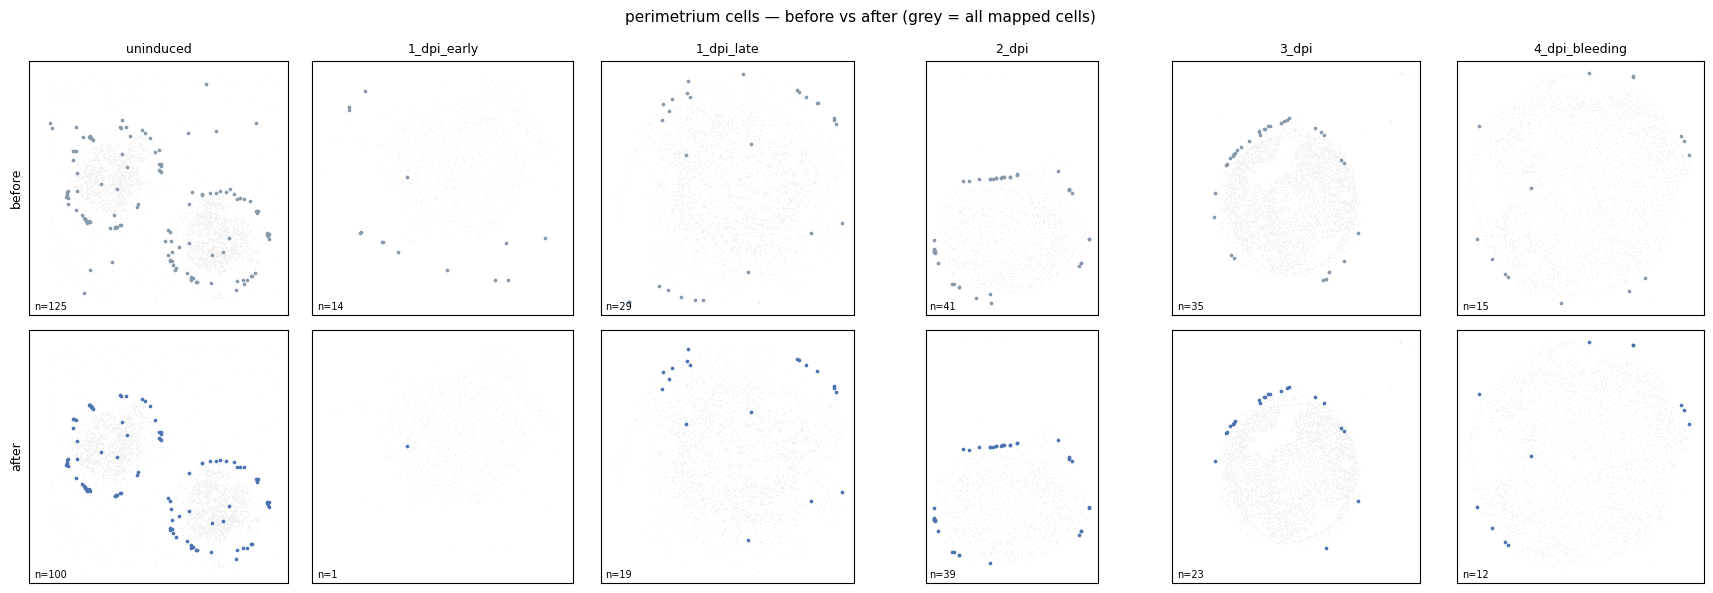

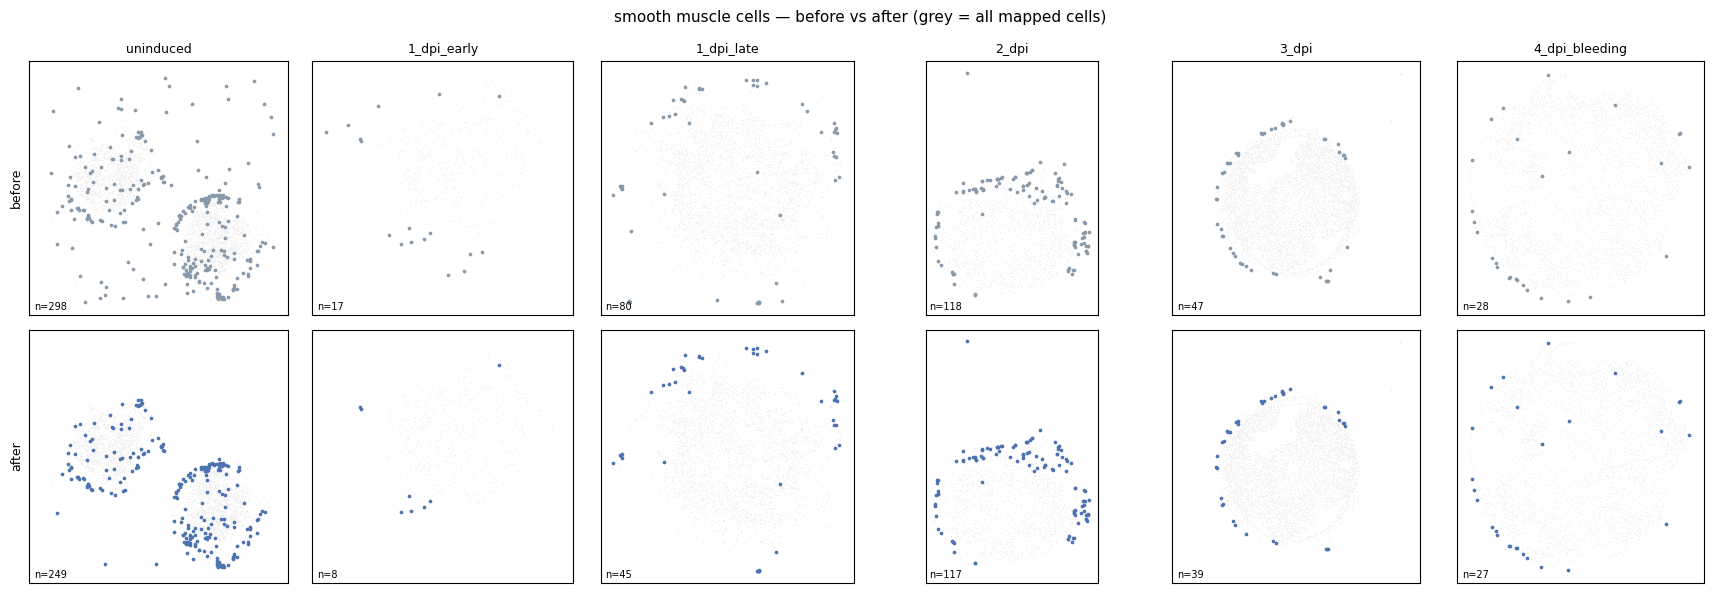

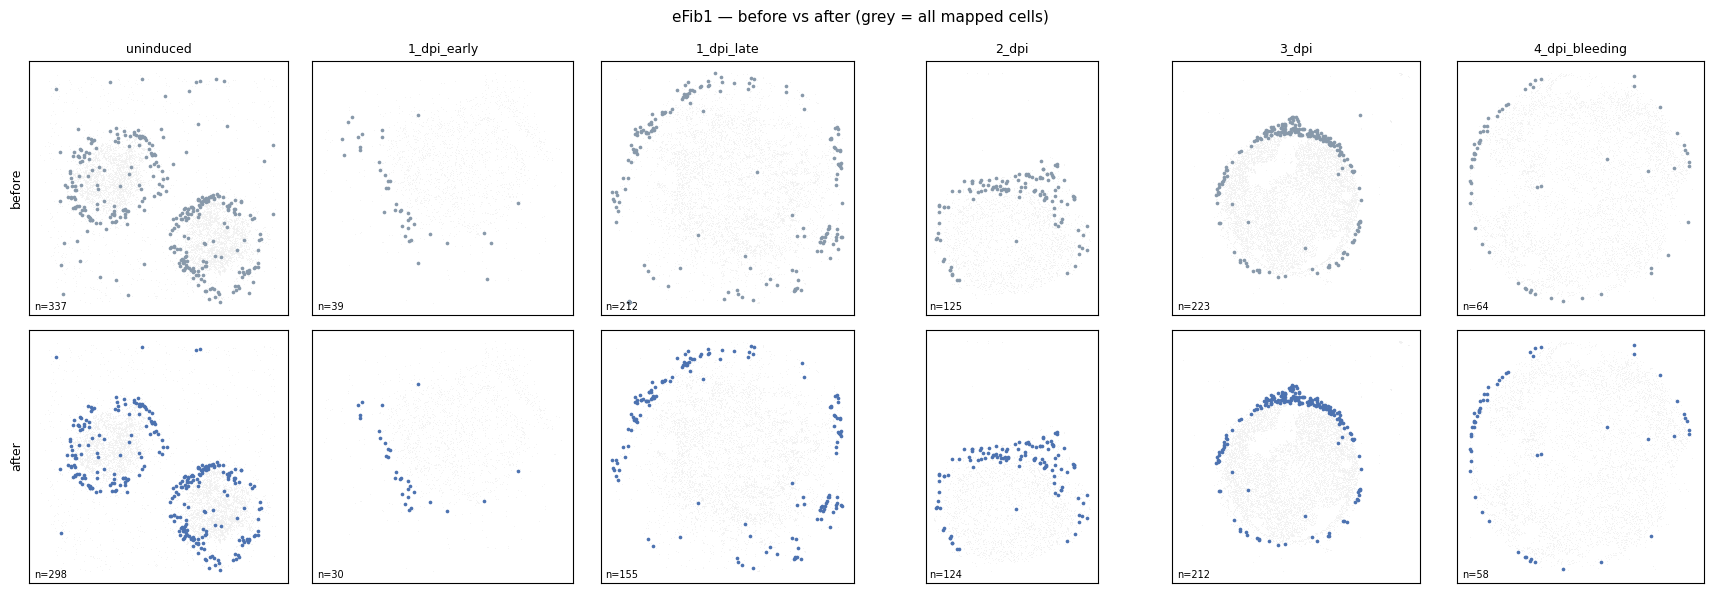

In [25]:
# ---- before / after, for the at-risk types ----------------------------------
TYPES = ["perimetrium cells", "smooth muscle cells", "eFib1"]

def type_mask(t):
    m = obs_f["coarse"].astype(str).eq(t)
    if "label" in obs_f: m = m | obs_f["label"].astype(str).eq(t)
    return m.values

rows = []
for t in TYPES:
    tm = type_mask(t)
    for tp in TPS:
        sel = tm & (obs[TIMEPOINT].astype(str) == tp).values & mapped.values
        kp  = sel & obs_f.reason.eq("kept").values
        if sel.sum() < 5: continue
        b, a = obs_f.loc[sel, "r_norm"], obs_f.loc[kp, "r_norm"]
        rows.append({"type": t, "timepoint": tp,
                     "n_before": int(sel.sum()), "n_after": int(kp.sum()),
                     "r_med_before": round(float(b.median()), 2),
                     "r_med_after":  round(float(a.median()), 2) if len(a) else np.nan,
                     "r_p90_before": round(float(b.quantile(.9)), 2),
                     "r_p90_after":  round(float(a.quantile(.9)), 2) if len(a) else np.nan})
shape = pd.DataFrame(rows)
shape["r_med_shift"] = (shape.r_med_after - shape.r_med_before).round(2)
print("radial profile before vs after (r_norm: 1.0 ~ tissue edge)")
print("shift near 0 = only strays trimmed; large negative = the outer rim was cut\n")
print(shape.set_index(["type", "timepoint"]).to_string())

for t in TYPES:
    tm = type_mask(t)
    fig, axes = plt.subplots(2, len(TPS), figsize=(2.9*len(TPS), 6.0), squeeze=False)
    for j, tp in enumerate(TPS):
        bg  = mapped.values & (obs[TIMEPOINT].astype(str) == tp).values
        sel = tm & bg
        kp  = sel & obs_f.reason.eq("kept").values
        for row, (m_, ttl, col) in enumerate([(sel, "before", "#8899aa"),
                                              (kp,  "after",  "#4C72B0")]):
            ax = axes[row][j]
            ax.scatter(obs.loc[bg, X], obs.loc[bg, Y], s=0.3, c="#f0f0f0", linewidths=0)
            ax.scatter(obs.loc[m_, X], obs.loc[m_, Y], s=7, c=col, linewidths=0)
            ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
            if row == 0: ax.set_title(tp, fontsize=9)
            if j == 0: ax.set_ylabel(ttl, fontsize=9)
            ax.text(0.02, 0.02, f"n={int(m_.sum())}", transform=ax.transAxes, fontsize=7)
    fig.suptitle(f"{t} — before vs after (grey = all mapped cells)", fontsize=11)
    fig.tight_layout(); plt.show()

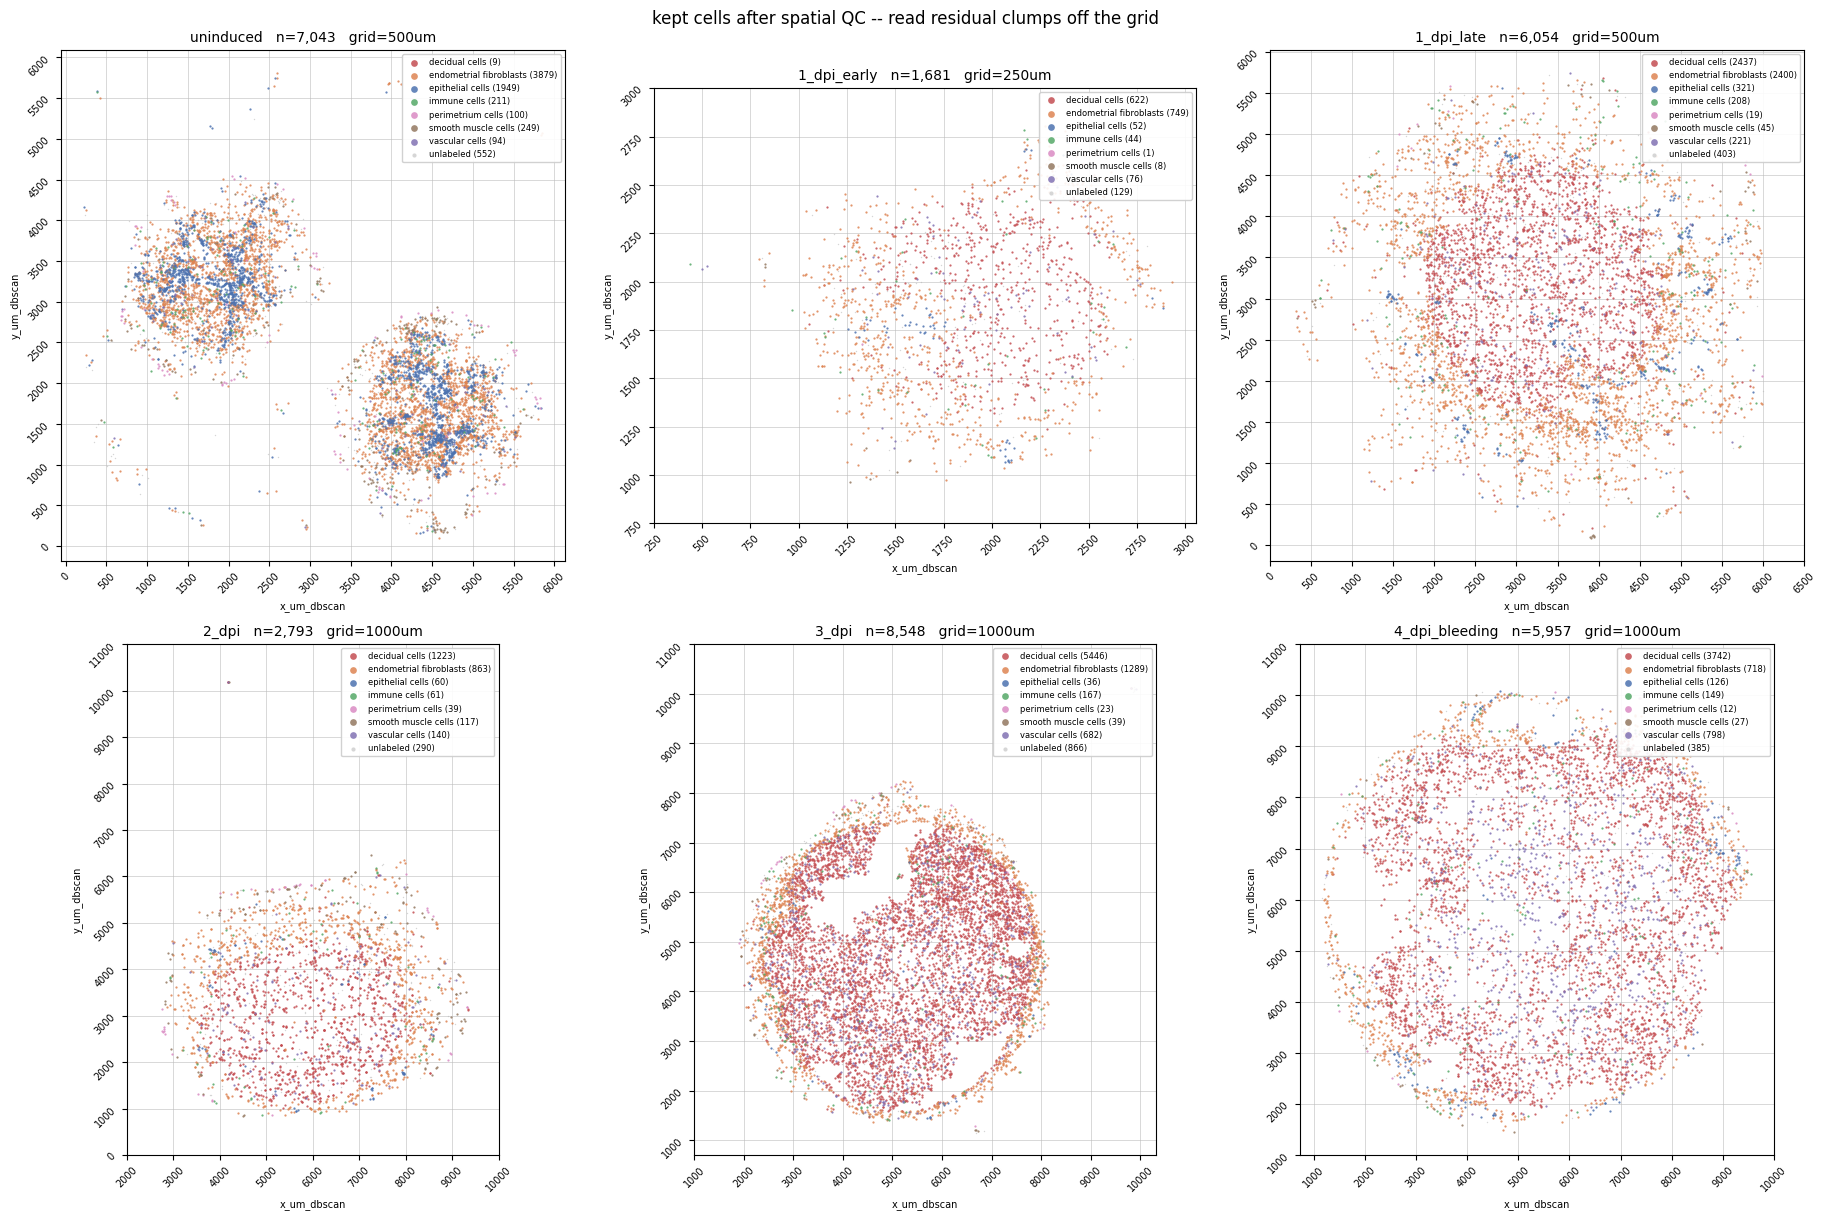

coordinate extents (for writing boxes):
                   n   x_min   x_max   y_min    y_max
timepoint                                            
1_dpi_early     1681   441.0  2932.0   964.0   2806.0
1_dpi_late      6054   312.0  6000.0    87.0   5739.0
2_dpi           2793  2760.0  9342.0   838.0  10195.0
3_dpi           8548  1897.0  9908.0  1148.0  10133.0
4_dpi_bleeding  5957  1151.0  9563.0  1461.0  10079.0
uninduced       7043   221.0  5847.0    99.0   5803.0

per puck within each panel (in case a timepoint holds two frames):
                                         n   x_min   x_max   y_min    y_max
timepoint      sample                                                      
1_dpi_early    1_dpi_early_mck1       1681   441.0  2932.0   964.0   2806.0
1_dpi_late     1_dpi_late_mck12a      4276   312.0  6000.0    87.0   5739.0
               1_dpi_late_mck12b      1778   340.0  5949.0   109.0   5659.0
2_dpi          2_dpi_mck15            2793  2760.0  9342.0   838.0  10195.0
3_dp

In [28]:
# ---- coordinate grid, kept cells only, coloured by cell type ----------------
PANEL_BY = TIMEPOINT          # switch to SAMPLE if a timepoint shows two blobs
GRID_UM  = None               # None = auto (~10 divisions); or set e.g. 2000
NCOL     = 3

panels = [p for p in (TPS if PANEL_BY == TIMEPOINT
                      else obs.loc[mapped, SAMPLE].astype(str).unique())]
CT_COL = {
    "decidual cells": "#C44E52", "endometrial fibroblasts": "#DD8452",
    "epithelial cells": "#4C72B0", "immune cells": "#55A868",
    "vascular cells": "#8172B3", "smooth muscle cells": "#937860",
    "perimetrium cells": "#DA8BC3", "unlabeled": "#cfcfcf",
}
kept = obs_f.reason.eq("kept").values

nrow = int(np.ceil(len(panels) / NCOL))
fig, axes = plt.subplots(nrow, NCOL, figsize=(6.2*NCOL, 6.2*nrow), squeeze=False)
for idx, p in enumerate(panels):
    ax = axes[idx // NCOL][idx % NCOL]
    m = kept & (obs[PANEL_BY].astype(str) == p).values
    if not m.sum():
        ax.axis("off"); continue
    sub = obs_f.loc[m]
    for ct in sorted(sub["coarse"].astype(str).unique(),
                     key=lambda c: (c == "unlabeled", c)):
        q = sub[sub["coarse"].astype(str) == ct]
        ax.scatter(q[X], q[Y], s=(1.0 if ct == "unlabeled" else 2.6),
                   c=CT_COL.get(ct, "#333333"), linewidths=0,
                   label=f"{ct} ({len(q)})", alpha=.85,
                   zorder=1 if ct == "unlabeled" else 2)
    x0, x1 = sub[X].min(), sub[X].max(); y0, y1 = sub[Y].min(), sub[Y].max()
    step = GRID_UM or max(round((max(x1-x0, y1-y0) / 10) / 500) * 500, 250)
    ax.set_xticks(np.arange(np.floor(x0/step)*step, x1+step, step))
    ax.set_yticks(np.arange(np.floor(y0/step)*step, y1+step, step))
    ax.grid(True, which="major", lw=.5, c="#bbbbbb", alpha=.8, zorder=0)
    ax.tick_params(labelsize=7, rotation=45); ax.set_aspect("equal")
    ax.set_title(f"{p}   n={int(m.sum()):,}   grid={step:.0f}um", fontsize=10)
    ax.set_xlabel(X, fontsize=7); ax.set_ylabel(Y, fontsize=7)
    ax.legend(fontsize=6, markerscale=3, loc="upper right", framealpha=.9)
for k in range(len(panels), nrow*NCOL): axes[k//NCOL][k%NCOL].axis("off")
fig.suptitle("kept cells after spatial QC -- read residual clumps off the grid", fontsize=12)
fig.tight_layout(); plt.show()

print("coordinate extents (for writing boxes):")
print((obs_f[kept].groupby(PANEL_BY, observed=True)
       .agg(n=(X,"size"), x_min=(X,"min"), x_max=(X,"max"),
            y_min=(Y,"min"), y_max=(Y,"max")).round(0)).to_string())
print("\nper puck within each panel (in case a timepoint holds two frames):")
print(obs_f[kept].groupby([TIMEPOINT, SAMPLE], observed=True)
      .agg(n=(X,"size"), x_min=(X,"min"), x_max=(X,"max"),
           y_min=(Y,"min"), y_max=(Y,"max")).round(0).to_string())

per box: how many KEPT cells it would blank, and which types

  {'timepoint': 'uninduced', 'y_gt': 5000}
      ->    24 cells   {'endometrial fibroblasts': 15, 'epithelial cells': 7, 'unlabeled': 1, 'immune cells': 1}
  {'timepoint': 'uninduced', 'x_lt': 500}
      ->    19 cells   {'unlabeled': 6, 'endometrial fibroblasts': 6, 'epithelial cells': 4, 'immune cells': 2}
  {'timepoint': 'uninduced', 'y_lt': 1500, 'x_lt': 3000}
      ->    51 cells   {'endometrial fibroblasts': 21, 'unlabeled': 15, 'epithelial cells': 8, 'immune cells': 3}
  {'timepoint': 'uninduced', 'x_gt': 2500, 'x_lt': 3000, 'y_gt': 1500, 'y_lt': 2000}
      ->     5 cells   {'endometrial fibroblasts': 3, 'epithelial cells': 1, 'immune cells': 1}
  {'timepoint': '1_dpi_early', 'x_lt': 750}
      ->     3 cells   {'vascular cells': 2, 'immune cells': 1}
  {'timepoint': '2_dpi', 'y_gt': 7000}
      ->     5 cells   {'decidual cells': 3, 'smooth muscle cells': 1, 'vascular cells': 1}
  {'timepoint': '3_dpi', 'y_gt': 9000

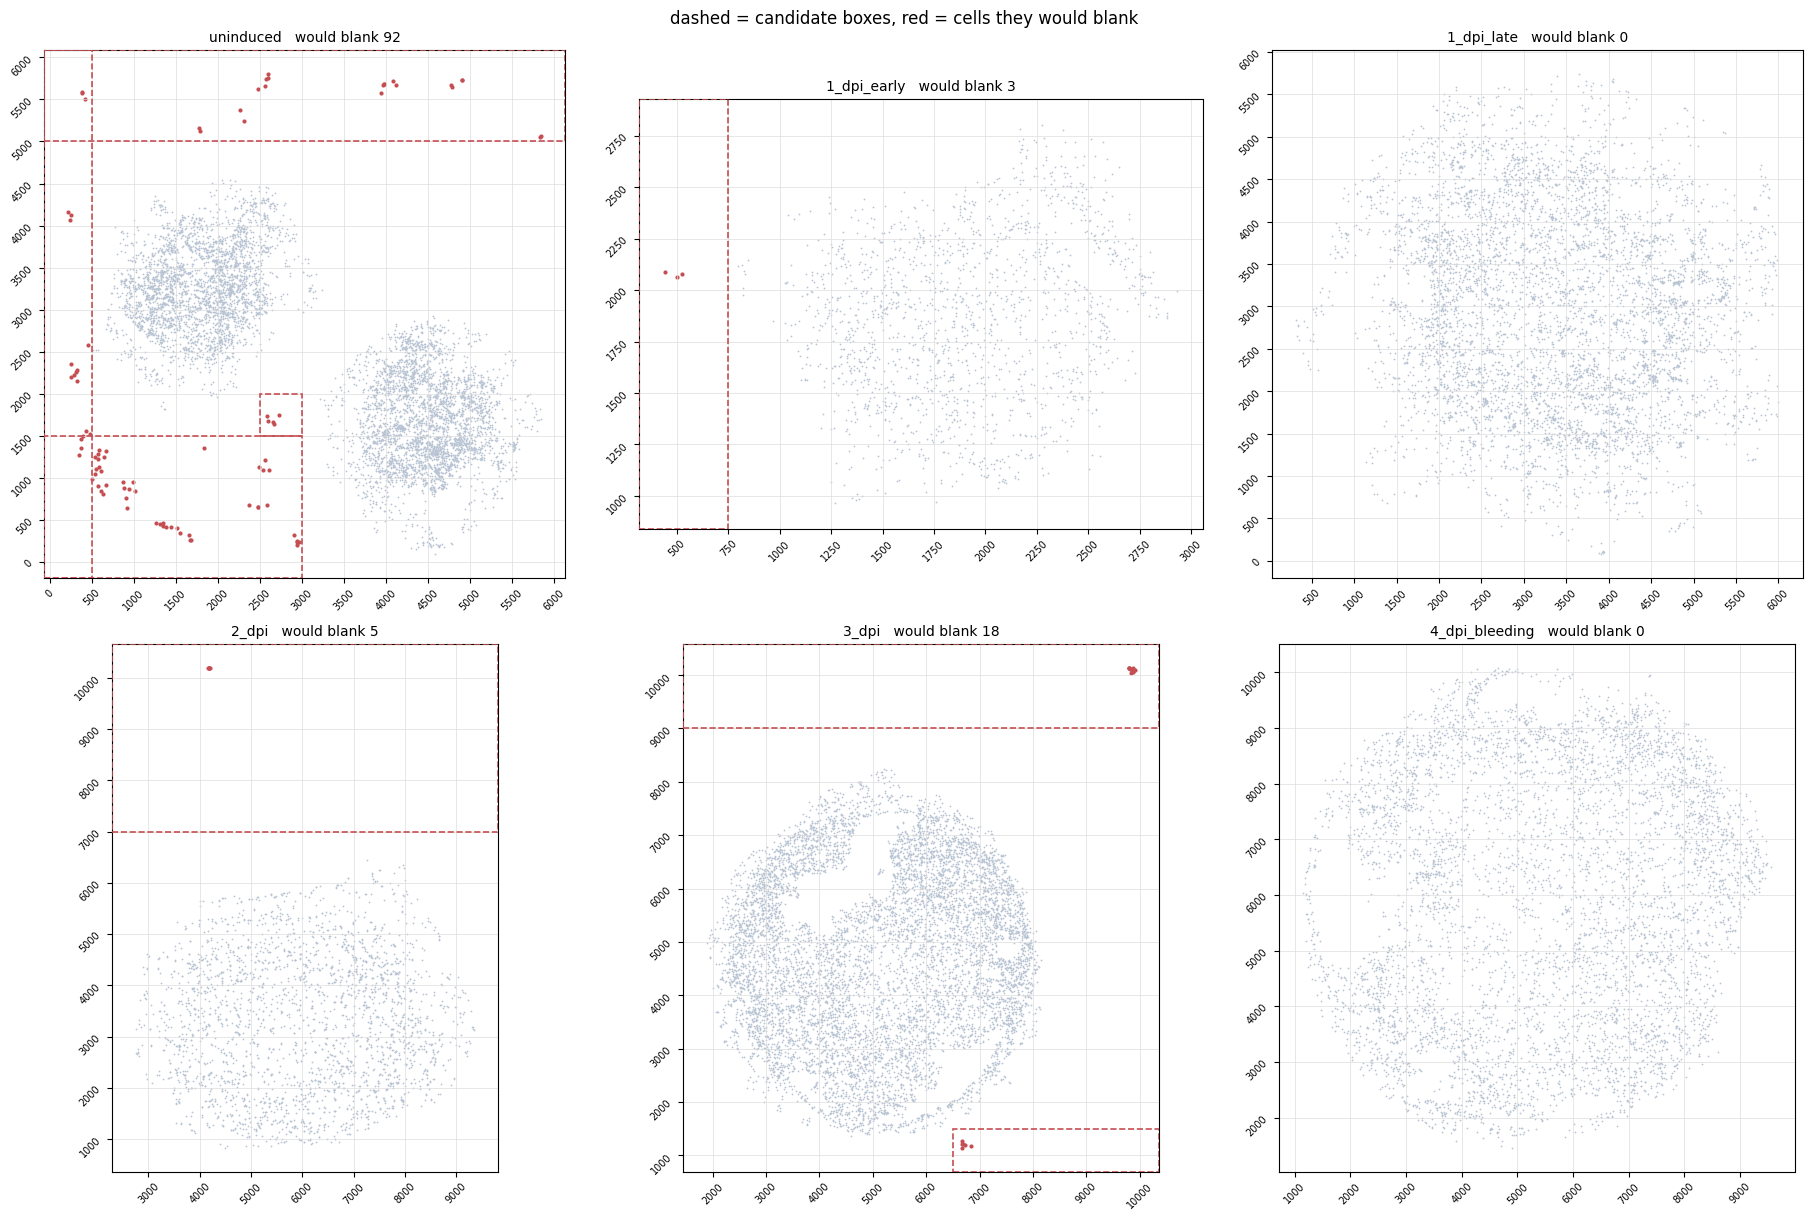

In [36]:
# ---- CANDIDATE exclusion boxes -- edit, re-run, repeat ----------------------
CANDIDATE_EXCLUSIONS = [
    # uninduced -- two pucks, everything outside their footprint
    {"timepoint": "uninduced",   "y_gt": 5000},
    {"timepoint": "uninduced",   "x_lt": 500},
    {"timepoint": "uninduced",   "y_lt": 1500, "x_lt": 3000},
    {"timepoint": "uninduced",   "x_gt": 2500, "x_lt": 3000, "y_gt": 1500, "y_lt": 2000},
    # 1_dpi_early
    {"timepoint": "1_dpi_early", "x_lt": 750},
    # 1_dpi_late -- clean, no box
    # 2_dpi
    {"timepoint": "2_dpi",       "y_gt": 7000},
    # 3_dpi
    {"timepoint": "3_dpi",       "y_gt": 9000},
    {"timepoint": "3_dpi",       "y_lt": 1500, "x_gt": 6500},
]
def rule_mask(r, base):
    m = base.copy()
    if "timepoint" in r: m &= (obs[TIMEPOINT].astype(str) == r["timepoint"]).values
    if "sample"    in r: m &= (obs[SAMPLE].astype(str) == r["sample"]).values
    if "x_gt" in r: m &= (obs[X] > r["x_gt"]).values
    if "x_lt" in r: m &= (obs[X] < r["x_lt"]).values
    if "y_gt" in r: m &= (obs[Y] > r["y_gt"]).values
    if "y_lt" in r: m &= (obs[Y] < r["y_lt"]).values
    return m

kept = obs_f.reason.eq("kept").values
cand = np.zeros(len(obs), bool)
print("per box: how many KEPT cells it would blank, and which types\n")
for r in CANDIDATE_EXCLUSIONS:
    m = rule_mask(r, kept); cand |= m
    print(f"  {r}\n      -> {int(m.sum()):>5} cells   "
          f"{obs_f.loc[m, 'coarse'].value_counts().head(4).to_dict()}")
print(f"\nTOTAL additional blanked: {int(cand.sum()):,} "
      f"({100*cand.sum()/max(kept.sum(),1):.2f}% of kept)")
print("\nby timepoint:"); print(pd.Series(obs.loc[cand, TIMEPOINT].astype(str)).value_counts().to_string())

NCOL = 3; nrow = int(np.ceil(len(TPS)/NCOL))
fig, axes = plt.subplots(nrow, NCOL, figsize=(6.2*NCOL, 6.2*nrow), squeeze=False)
for idx, tp in enumerate(TPS):
    ax = axes[idx//NCOL][idx%NCOL]
    m = kept & (obs[TIMEPOINT].astype(str) == tp).values
    if not m.sum(): ax.axis("off"); continue
    sub = obs_f.loc[m]
    x0,x1 = sub[X].min(), sub[X].max(); y0,y1 = sub[Y].min(), sub[Y].max()
    pad = .05*max(x1-x0, y1-y0)
    ax.scatter(obs.loc[m & ~cand, X], obs.loc[m & ~cand, Y], s=1.6, c="#b8c4d4", linewidths=0)
    ax.scatter(obs.loc[m & cand, X],  obs.loc[m & cand, Y],  s=9, c="#C44E52", linewidths=0)
    for r in CANDIDATE_EXCLUSIONS:
        if r.get("timepoint") not in (None, tp): continue
        bx0 = r.get("x_gt", x0-pad); bx1 = r.get("x_lt", x1+pad)
        by0 = r.get("y_gt", y0-pad); by1 = r.get("y_lt", y1+pad)
        ax.add_patch(plt.Rectangle((bx0, by0), bx1-bx0, by1-by0, fill=False,
                                   ec="#C44E52", lw=1.2, ls="--", zorder=5))
    step = max(round((max(x1-x0, y1-y0)/10)/500)*500, 250)
    ax.set_xticks(np.arange(np.floor(x0/step)*step, x1+step, step))
    ax.set_yticks(np.arange(np.floor(y0/step)*step, y1+step, step))
    ax.grid(True, lw=.5, c="#dddddd", zorder=0); ax.tick_params(labelsize=7, rotation=45)
    ax.set_xlim(x0-pad, x1+pad); ax.set_ylim(y0-pad, y1+pad); ax.set_aspect("equal")
    ax.set_title(f"{tp}   would blank {int(dropm.sum()) if False else int((m & cand).sum())}", fontsize=10)
for k in range(len(TPS), nrow*NCOL): axes[k//NCOL][k%NCOL].axis("off")
fig.suptitle("dashed = candidate boxes, red = cells they would blank", fontsize=12)
fig.tight_layout(); plt.show()

In [35]:
# ---- what IS the thing in the middle of 3_dpi? ------------------------------
ISLAND = {"timepoint": "3_dpi", "x_gt": 5000, "x_lt": 6000, "y_gt": 6000, "y_lt": 7000}

kept = obs_f.reason.eq("kept").values
isl  = rule_mask(ISLAND, kept)
rest = kept & (obs[TIMEPOINT].astype(str) == "3_dpi").values & ~isl
print(f"island n={int(isl.sum()):,}   rest of 3_dpi n={int(rest.sum()):,}\n")

comp = pd.DataFrame({
    "island_n": obs_f.loc[isl, "coarse"].value_counts(),
    "island_%": (100*obs_f.loc[isl, "coarse"].value_counts(normalize=True)).round(1),
    "rest_%":   (100*obs_f.loc[rest,"coarse"].value_counts(normalize=True)).round(1)}).fillna(0)
comp["enrich"] = (comp["island_%"] / comp["rest_%"].replace(0, np.nan)).round(2)
print("cell-type composition:"); print(comp.sort_values("enrich", ascending=False).to_string())
if "label" in obs_f:
    print(f"\nfinest labels:\n{obs_f.loc[isl,'label'].value_counts().head(8).to_string()}")

QC = [c for c in ["n_genes_by_counts","total_counts","pct_counts_mt","pct_counts_ribo",
                  "doubletdetection_doublet_score"] if c in obs.columns]
print("\nQC island vs rest (medians):")
print(pd.DataFrame({"island": obs_f.loc[isl,QC].median(), "rest": obs_f.loc[rest,QC].median(),
                    "ratio": (obs_f.loc[isl,QC].median()/obs_f.loc[rest,QC].median()).round(2)}
                   ).round(1).to_string())
print(f"\nkNN mean dist: island {obs_f.loc[isl,'score2'].median():.0f}um  "
      f"rest {obs_f.loc[rest,'score2'].median():.0f}um  (higher = isolated)")

sub = adata[(isl | rest)].copy()
sub.obs["grp"] = np.where(isl[(isl | rest)], "island", "rest")
if float(sub.X.max()) > 50:
    sc.pp.normalize_total(sub, target_sum=1e4); sc.pp.log1p(sub)
sc.tl.rank_genes_groups(sub, "grp", groups=["island"], reference="rest", method="wilcoxon")
print("\ntop genes enriched in the island:")
print(sc.get.rank_genes_groups_df(sub, group="island").head(25)[
      ["names","logfoldchanges","pvals_adj"]].round(3).to_string(index=False))

MARK = {"luminal epi": ["Wnt7a","Muc1","Lgr5"], "glandular": ["Foxa2","Ihh","Lif"],
        "epithelial": ["Cdh1","Pax8"], "immune": ["Ptprc","C1qa","Adgre1"],
        "blood/vessel": ["Hba-a1","Hbb-bs","Pecam1","Flt1"], "smc": ["Acta2","Myh11"],
        "stress/death": ["Hspa1a","Jun","Fos"]}
rows = []
for k, gs in MARK.items():
    gs = [g for g in gs if g in sub.var_names]
    if not gs: continue
    v = sub[:, gs].X; v = v.toarray() if hasattr(v, "toarray") else v
    rows.append({"panel": k, "genes": ",".join(gs),
                 "island": round(float(v[sub.obs.grp.eq("island").values].mean()), 3),
                 "rest": round(float(v[sub.obs.grp.eq("rest").values].mean()), 3)})
mk = pd.DataFrame(rows); mk["ratio"] = (mk.island/mk.rest.replace(0,np.nan)).round(2)
print("\nmarker panel means:"); print(mk.to_string(index=False))

island n=326   rest of 3_dpi n=8,222

cell-type composition:
                         island_n  island_%  rest_%  enrich
coarse                                                     
immune cells                 15.0       4.6     1.8    2.56
decidual cells              241.0      73.9    63.3    1.17
vascular cells               26.0       8.0     8.0    1.00
unlabeled                    29.0       8.9    10.2    0.87
epithelial cells              1.0       0.3     0.4    0.75
endometrial fibroblasts      14.0       4.3    15.5    0.28
smooth muscle cells           0.0       0.0     0.5    0.00
perimetrium cells             0.0       0.0     0.3    0.00

finest labels:
label
dec2              224
unlabeled          29
vascular cells     26
dec3               16
immune cells       15
eFib3               7
eFib2i              4
eFibP               2

QC island vs rest (medians):
                                island    rest  ratio
n_genes_by_counts               1828.0  1711.0    1.1
tot

               sample      timepoint   deg    n   cx   cy
      uninduced_mck8a      uninduced   0.0 4075 3728 2446
      uninduced_mck8b      uninduced   0.0 3573 3755 2449
     1_dpi_early_mck1    1_dpi_early 104.0 1775 1886 1882
    1_dpi_late_mck12a     1_dpi_late   0.0 4348 3421 2930
    1_dpi_late_mck12b     1_dpi_late   0.0 3086 3187 3036
          2_dpi_mck15          2_dpi 240.3 2909 6143 3280
         3_dpi_mck10a          3_dpi 210.0 4110 5210 4731
         3_dpi_mck10b          3_dpi 210.0 4588 5159 4747
4_dpi_bleeding_mck11a 4_dpi_bleeding   0.0 5996 5544 6047

sanity: spread before 2789um, after 2807um


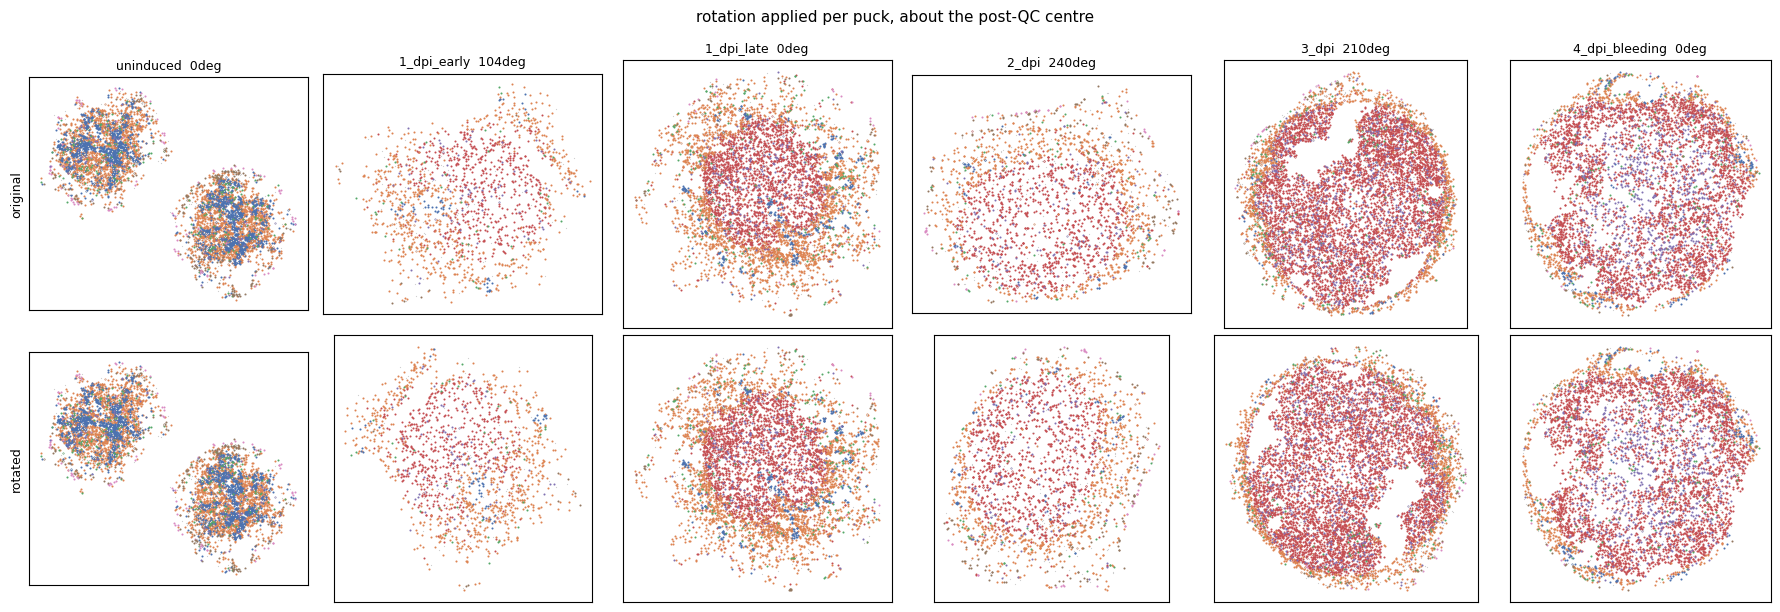

In [42]:
# ---- rotate each puck so tissue is oriented consistently ---------------------
TP_ROTATIONS = {
    "uninduced":      0.0,
    "1_dpi_early":  104.0,
    "1_dpi_late":     0.0,
    "2_dpi":        240.3,
    "3_dpi":        210.0,
    "4_dpi_bleeding": 0.0,     # was '4_dpi' in the old script -- key renamed
}

have = set(obs[TIMEPOINT].astype(str).unique())
missing, extra = have - set(TP_ROTATIONS), set(TP_ROTATIONS) - have
if missing: print(f"!! no angle for: {sorted(missing)} (defaulting to 0)")
if extra:   print(f"!! angle given for absent timepoint(s): {sorted(extra)}")

def rotate_about(x, y, degrees, cx, cy):
    if degrees % 360 == 0:
        return x.copy(), y.copy()
    r = np.radians(degrees); ca, sa = np.cos(r), np.sin(r)
    dx, dy = x - cx, y - cy
    return cx + ca*dx - sa*dy, cy + sa*dx + ca*dy

xr = obs[X].astype(float).copy(); yr = obs[Y].astype(float).copy()
kept = obs_f.reason.eq("kept").values
rows = []
for s in obs.loc[mapped, SAMPLE].astype(str).unique():
    m  = mapped.values & (obs[SAMPLE].astype(str) == s).values
    mk = m & kept
    tp = obs.loc[m, TIMEPOINT].astype(str).iloc[0]
    deg = TP_ROTATIONS.get(tp, 0.0)
    src = mk if mk.sum() >= 20 else m
    cx, cy = float(obs.loc[src, X].median()), float(obs.loc[src, Y].median())
    nx, ny = rotate_about(obs.loc[m, X].to_numpy(float),
                          obs.loc[m, Y].to_numpy(float), deg, cx, cy)
    xr.loc[m], yr.loc[m] = nx, ny
    rows.append({"sample": s, "timepoint": tp, "deg": deg, "n": int(m.sum()),
                 "cx": round(cx), "cy": round(cy)})
print(pd.DataFrame(rows).to_string(index=False))

obs_f["x_rot"], obs_f["y_rot"] = xr.values, yr.values
chk = obs_f.loc[kept & mapped.values]
print(f"\nsanity: spread before {np.hypot(*(chk[[X,Y]].std().values)):.0f}um, "
      f"after {np.hypot(*(chk[['x_rot','y_rot']].std().values)):.0f}um")

fig, axes = plt.subplots(2, len(TPS), figsize=(3.0*len(TPS), 6.2), squeeze=False)
for j, tp in enumerate(TPS):
    m = kept & (obs[TIMEPOINT].astype(str) == tp).values
    for row, (xc, yc, ttl) in enumerate([(X, Y, "original"), ("x_rot", "y_rot", "rotated")]):
        ax = axes[row][j]; sub = obs_f.loc[m]
        for ct in sorted(sub["coarse"].astype(str).unique(), key=lambda c: (c=="unlabeled", c)):
            q = sub[sub["coarse"].astype(str) == ct]
            ax.scatter(q[xc], q[yc], s=(0.8 if ct=="unlabeled" else 2.2),
                       c=CT_COL.get(ct, "#333"), linewidths=0)
        ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
        if row == 0: ax.set_title(f"{tp}  {TP_ROTATIONS.get(tp,0):.0f}deg", fontsize=9)
        if j == 0: ax.set_ylabel(ttl, fontsize=9)
fig.suptitle("rotation applied per puck, about the post-QC centre", fontsize=11)
fig.tight_layout(); plt.show()

In [38]:
# ---- apply the final exclusion boxes, then BLANK the coordinates -------------
FINAL_EXCLUSIONS = [
    # uninduced -- two pucks; everything outside their footprint
    {"timepoint": "uninduced",   "y_gt": 5000},
    {"timepoint": "uninduced",   "x_lt": 500},
    {"timepoint": "uninduced",   "y_lt": 1500, "x_lt": 3000},
    {"timepoint": "uninduced",   "x_gt": 2500, "x_lt": 3000, "y_gt": 1500, "y_lt": 2000},
    # 1_dpi_early
    {"timepoint": "1_dpi_early", "x_lt": 750},
    # 1_dpi_late -- clean, no box
    # 2_dpi
    {"timepoint": "2_dpi",       "y_gt": 7000},
    # 3_dpi   (no box for the central island -- that's real tissue)
    {"timepoint": "3_dpi",       "y_gt": 9000},
    {"timepoint": "3_dpi",       "y_lt": 1500, "x_gt": 6500},
]

kept0 = obs_f.reason.eq("kept").values
boxed = np.zeros(len(obs), bool)
for r in FINAL_EXCLUSIONS:
    m = rule_mask(r, kept0); boxed |= m
    print(f"  {r}\n      -> {int(m.sum()):>5} cells  "
          f"{obs_f.loc[m, 'coarse'].value_counts().head(3).to_dict()}")
obs_f.loc[boxed, "reason"] = "boxed"

ORDER = ["kept", "far", "degenerate", "boxed", "unmapped"]
COL["boxed"] = "#8172B3"

# blank: a bad position becomes NO position, joining the existing unmapped pool
kept = obs_f.reason.eq("kept").values
obs_f["x_qc"] = np.where(kept, obs[X].astype(float), np.nan)
obs_f["y_qc"] = np.where(kept, obs[Y].astype(float), np.nan)
XQ, YQ = "x_qc", "y_qc"

print(f"\nboxed {int(boxed.sum()):,} additional cells\n\nfinal tally:")
tal = obs_f.groupby("reason", observed=True).size().reindex(ORDER).fillna(0).astype(int)
print(pd.DataFrame({"n": tal, "%": (100*tal/len(obs)).round(1)}).to_string())
print(f"\ncells WITH usable coordinates: {int(kept.sum()):,} "
      f"({100*kept.mean():.1f}% of all, {100*kept.sum()/max(mapped.sum(),1):.1f}% of mapped)")
print(f"cells retained in the object: {len(obs):,} (blanking removes nothing)")
print("\nper timepoint:")
print(pd.crosstab(obs[TIMEPOINT].astype(str), obs_f["reason"])
      .reindex(columns=ORDER, fill_value=0).to_string())
print("\nboxed cells by type (should be mostly unlabeled):")
print(obs_f.loc[boxed, "coarse"].value_counts().to_string())

  {'timepoint': 'uninduced', 'y_gt': 5000}
      ->    24 cells  {'endometrial fibroblasts': 15, 'epithelial cells': 7, 'unlabeled': 1}
  {'timepoint': 'uninduced', 'x_lt': 500}
      ->    19 cells  {'unlabeled': 6, 'endometrial fibroblasts': 6, 'epithelial cells': 4}
  {'timepoint': 'uninduced', 'y_lt': 1500, 'x_lt': 3000}
      ->    51 cells  {'endometrial fibroblasts': 21, 'unlabeled': 15, 'epithelial cells': 8}
  {'timepoint': 'uninduced', 'x_gt': 2500, 'x_lt': 3000, 'y_gt': 1500, 'y_lt': 2000}
      ->     5 cells  {'endometrial fibroblasts': 3, 'epithelial cells': 1, 'immune cells': 1}
  {'timepoint': '1_dpi_early', 'x_lt': 750}
      ->     3 cells  {'vascular cells': 2, 'immune cells': 1}
  {'timepoint': '2_dpi', 'y_gt': 7000}
      ->     5 cells  {'decidual cells': 3, 'smooth muscle cells': 1, 'vascular cells': 1}
  {'timepoint': '3_dpi', 'y_gt': 9000}
      ->    12 cells  {'unlabeled': 8, 'vascular cells': 2, 'decidual cells': 2}
  {'timepoint': '3_dpi', 'y_lt': 1500, 'x_

## 10. Decide

Pick from §5 (how much), §6 (do they agree), §7 (does connectivity replace the
hand-picked boxes) and §8 (does it look right). Then set in
`config/config.yaml`:

```yaml
spatial_qc:
  mode: mad            # or quantile / absolute / off
  n_mads: 3.0
  log_scale: true
  largest_component: true
  lcc_radius_factor: 3.0
```

and run `snakemake --profile profiles/slurm data/interim/qc_spatial_mouse.h5ad`
to materialise it. Human is unchanged (`mode: off` if you want it untouched).